In [1]:
library(tidyverse)
library(tximport)
library(DESeq2)
library(rtracklayer)
library(edgeR)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’

In [2]:
#specifying plot aesthetics
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15), rect=element_rect(linewidth=1)))

In [3]:
#this is a list of paths to all RSEM files for the stimulus + BRM014 experiment. I'll filter this below to only include vehicle (n=2) or BRM014 (n=2) datasets at t=6h
files <- read.delim("/mnt/storage/home/agulka/projects/gm12878_stim_rnaseq/rsem_files.txt",sep='\t', header=F)

In [4]:
#Generate row metadata usign GENCODE annotations

#GENCODE annotations
gtf.file <- "/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.gtf.gz" #comprehensive gene annotation file, from https://www.gencodegenes.org/human/
gencode <- import(gtf.file) #read in file
gencode <- gencode[which(gencode$type=="gene")] #filter to only include gene-level annotations
#read in TSS coordinates w/ genes
gencode_tss <- read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.transcripts_tss.1kb.bed", header=F, sep='\t')

#more restrictive set only using protein-coding transcripts with ENSEMBL canonical flag 
#this is the set that will be used for identifying invariant TSS
ensembl_tss <- read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/ENSEMBL/ensembl.canonical.prot-coding.transcript.tss1kb.bed", header=F, sep='\t')

In [5]:
#generate rowdata
row.data <- data.frame(gencode@elementMetadata)
rownames(row.data) <- row.data$gene_id
row.data$gene_id <- NULL
#generate column with cleaned ENSEMBL IDs
row.data$gene_id_base <- gsub("\\..*$", "", rownames(row.data)) 
#remove NA columns
row.data <- row.data[,colSums(is.na(row.data))<nrow(row.data)]
# add genome coordinates
row.data$chr <- as.character(gencode@seqnames)
row.data$start <- as.numeric(gencode@ranges@start)
row.data$end <- row.data$start + as.numeric(gencode@ranges@width)

In [6]:
#read in RSEM data using tximport
txi <- tximport(files=files[grep("T6_BRM_r|T6_DMSO_r", files$V1),], txIn=F, type="rsem")

#filter to remove lowly expressed genes
filt <- which(apply(txi$abundance, MARGIN=1, FUN=max) <=1 | apply(txi$length, MARGIN=1, FUN=min)==0)

txi$abundance <- txi$abundance[-filt,]
txi$counts <- txi$counts[-filt,]
txi$length <- txi$length[-filt,]

#subset row metadata to only include genes to be assayed
row.data <- row.data[match(gsub("\\..*$", "", rownames(txi$abundance)), row.data$gene_id_base),]

#make coldata
col.data <- data.frame("condition"=c("brm", "brm", "dmso", "dmso"), rep=c(1,2,1,2))

reading in files with read_tsv

1 
2 
3 
4 




In [7]:
#run differential gene expression analysis
dds <- DESeqDataSetFromTximport(txi, colData=col.data, design = ~condition)
dds$condition <- relevel(dds$condition, ref="dmso")
des <- DESeq(dds)
res <- results(des)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [8]:
#Identify genes that are unchanging with BRM014 treatment
#Criteria: p.adj > 0.2, 0.8 < fold change < 1.2 - these criteria were chosen to be consistent with publisehd work: Barisic et al., Nature, 2019; PMID: 30996347
no_change <- which(res$padj > 0.2 & res$log2FoldChange > log2(0.8) & res$log2FoldChange < log2(1.2))
#get genome coordinates for nc promoters
row.data_nc <- row.data[no_change,] %>% filter(!is.na(gene_name))

In [9]:
str(row.data_nc)

'data.frame':	6263 obs. of  13 variables:
 $ source      : Factor w/ 2 levels "HAVANA","ENSEMBL": 1 1 1 1 1 1 1 1 1 1 ...
 $ type        : Factor w/ 8 levels "gene","transcript",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ gene_type   : chr  "protein_coding" "protein_coding" "protein_coding" "protein_coding" ...
 $ gene_name   : chr  "DPM1" "SCYL3" "FIRRM" "NFYA" ...
 $ level       : chr  "2" "2" "2" "2" ...
 $ tag         : chr  NA NA NA NA ...
 $ hgnc_id     : chr  "HGNC:3005" "HGNC:19285" "HGNC:25565" "HGNC:7804" ...
 $ havana_gene : chr  "OTTHUMG00000032742.2" "OTTHUMG00000035941.6" "OTTHUMG00000035821.9" "OTTHUMG00000014669.1" ...
 $ artif_dupl  : chr  NA NA NA NA ...
 $ gene_id_base: chr  "ENSG00000000419" "ENSG00000000457" "ENSG00000000460" "ENSG00000001167" ...
 $ chr         : chr  "chr20" "chr1" "chr1" "chr6" ...
 $ start       : num  5.09e+07 1.70e+08 1.70e+08 4.11e+07 2.44e+07 ...
 $ end         : num  5.10e+07 1.70e+08 1.70e+08 4.11e+07 2.45e+07 ...


In [9]:
#make GRanges of non-changing gene coordinates
row.data_nc_gr <- GRanges(seqnames=row.data_nc$chr, ranges=IRanges(start=row.data_nc$start, end=row.data_nc$end))

#read in consensus peak set, filtered and with cRE type annotations (from ../filtered/filter_peaks.ipynb)
consensus_annot <- read.delim("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/filtered/consensus_filt_annot.tsv",sep='\t')
#make granges from consensus peak set
consensus_annot_gr <- GRanges(seqnames=consensus_annot$seqnames, ranges=IRanges(start=consensus_annot$start, end=consensus_annot$end))

#get TSS coordinates for nonchanging genes using ENSEMBL reference, and make GRanges object
tss_nc <- ensembl_tss[ensembl_tss$V4 %in% row.data$gene_name[no_change],]
tss_nc_gr <- GRanges(seqnames=tss_nc$V1, ranges=IRanges(start=tss_nc$V2, end=tss_nc$V3))

#filter consensus_annot to only include promoters that overlap with coordinates of invariantly expressed genes
consensus_filt <- consensus_annot[which(countOverlaps(consensus_annot_gr, tss_nc_gr) > 0 ),] %>% filter(type=="prom")
#write out as BED file - this will be used to generate a counts matrix over these control regions using bedtools multicov
#write.table(consensus_filt[,1:3] %>% mutate(ID=seq(1,nrow(consensus_filt))), "invariant_promoters_6h.bed", row.names=F, col.names=F,quote=F, sep='\t')

In [2]:
consensus_annot <- read.delim("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/filtered/consensus_filt_annot.tsv",sep='\t')

In [3]:
#read in control regions counts matrix
countmat_control <- read.delim("~/projects/poised_enh_manuscript/inputs/countmat/brm10uM_6h/invariant_promoters_6h.tsv", sep='\t', header=F)
#calculate effective library sizes (total counts per sample across control regions)
sizes <- colSums(countmat_control[,5:10])

#read in counts matrix over all consensus ATAC-seq peaks
countmat <- read.delim("~/projects/poised_enh_manuscript/inputs/countmat/brm10uM_6h/consensus_filt_counts.tsv", sep='\t', header=F)
counts <- countmat[,5:10]

In [4]:
dar <- function(data, coldata) {
    library(edgeR)
  
  # Create DGEList object with counts and group information
    dge <- DGEList(counts = data, group = coldata$Condition)
  
  # Override default library size with effective library sizes from control regions
    dge$samples$lib.size <- coldata$sizes
  
  # Set normalization factors to 1 (i.e., use lib.size as-is with no further scaling)
    dge$samples$norm.factors <- rep(1, nrow(coldata))
  
  # Create design matrix for comparison (model without intercept, group-specific columns)
    design <- model.matrix(~0 + group, data = dge$samples)
    colnames(design) <- levels(dge$samples$group)  # optional: label columns by condition names
  
  # Estimate dispersion 
    dge <- estimateDisp(dge, design)
  
  # Fit generalized linear model (GLM) 
    dge_fit <- glmQLFit(dge, design)
  
  # Conduct differential test (treatment vs control)
    diff <- glmQLFTest(dge_fit, contrast = c(1, -1))
  
  # Return all regions without sorting; include logFC, p-value, FDR, etc.
    res <- topTags(diff, n = Inf, sort.by = "none")$table 
  # Add column categorizing peaks as gaining, losing, or not changing accessibility
    res <- res %>% mutate(
                    change = case_when(FDR < 0.05 & logFC > log2(1.5) ~ "up",
                                       FDR < 0.05 & logFC < -log2(1.5) ~ "down",
                                       TRUE ~ "nc"))
  return(res)
}

dar_splitTSS <- function(data, coldata, rowdata){ 
    #Use row metadata to split counts matrix into TSS-proximal and dista
    #Run DAR analysis separately on each
    #filt <- apply(data, 1, max) > 10
    #data <- data[filt,]
    #rowdata <- rowdata[filt,]
    res_tss <- dar(data=data[rowdata$TSS==TRUE,], coldata)
    res_nontss <- dar(data=data[rowdata$TSS==FALSE,], coldata)

    #combine TSS and nonTSS DAR results
    res <- rbind(res_tss, res_nontss)
    #reorder rowdata
    rowdata <- rbind(rowdata[rowdata$TSS==TRUE,], rowdata[rowdata$TSS==FALSE,])
    return(list("results"=res, "row_meta"=rowdata))
}

In [5]:
coldata <- data.frame("Condition"=c("dmso", "dmso", "dmso", "brm", "brm", "brm"), "Replicate"=c(1,2,3,1,2,3), "sizes"=sizes)

In [13]:
#using default library size normalization

dge <- DGEList(counts=counts, group=coldata$Condition)
dge <- calcNormFactors(dge)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge$samples)
dge <- estimateDisp(dge, design)

#run DAR analysis
dge_fit <- glmQLFit(dge)
diff <- glmQLFTest(dge_fit, contrast=c(1,-1))
res <- topTags(diff, n=Inf)$table %>% mutate(
                    change = case_when(FDR < 0.05 & logFC > log2(1.5) ~ "up",
                                       FDR < 0.05 & logFC < -log2(1.5) ~ "down",
                                       TRUE ~ "nc"))

In [14]:
#summarize # that change (gain/lose accessibility) or do not using this method
res %>% group_by(change) %>% summarize(n())

change,n()
<chr>,<int>
down,34619
nc,51799
up,25303


In [15]:
#now using invariant promoter counts as effective library sizes
res_norm <- dar(counts, coldata)

In [16]:
#count as above
res_norm %>% group_by(change) %>% summarize(n()) 


change,n()
<chr>,<int>
down,57282
nc,53486
up,953


In [17]:
#sanity check on control regions
dge_control <- DGEList(counts=countmat_control[,5:10], group=coldata$Condition)
dge_control <- calcNormFactors(dge_control)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge_control$samples)
dge_control <- estimateDisp(dge_control, design)

#run DAR analysis
dge_control_fit <- glmQLFit(dge_control)
diff_control <- glmQLFTest(dge_control_fit, contrast=c(1,-1))
res_control <- topTags(diff_control, n=Inf)$table %>% mutate(
                    change = case_when(FDR < 0.05 & logFC > log2(1.5) ~ "up",
                                       FDR < 0.05 & logFC < -log2(1.5) ~ "down",
                                       TRUE ~ "nc"))

In [18]:
res_control %>% group_by(change) %>% summarize(n()) 

change,n()
<chr>,<int>
down,60
nc,4978


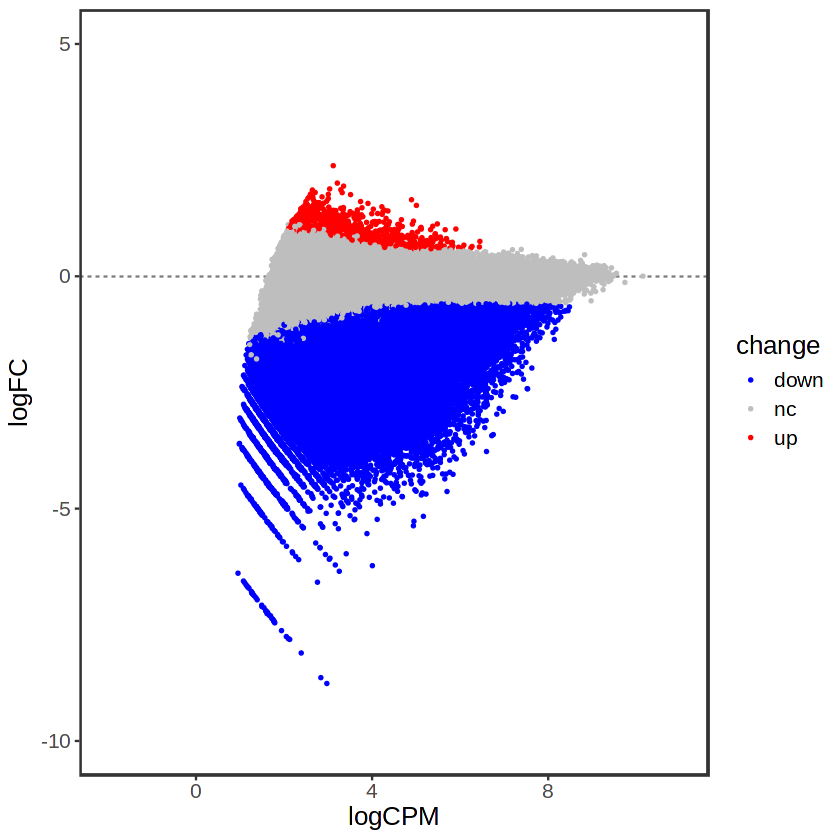

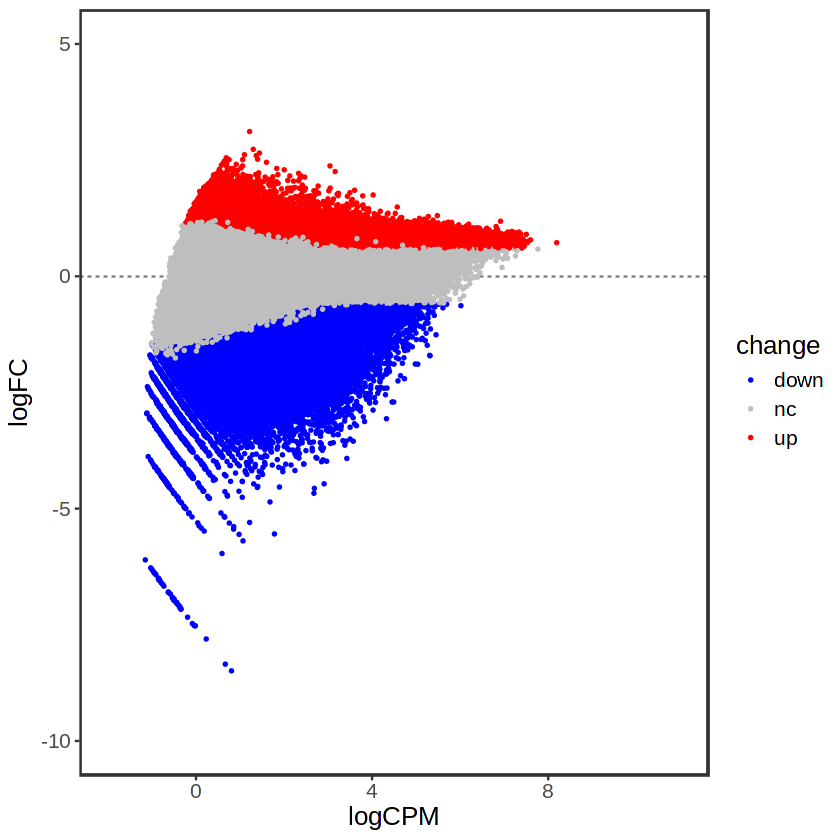

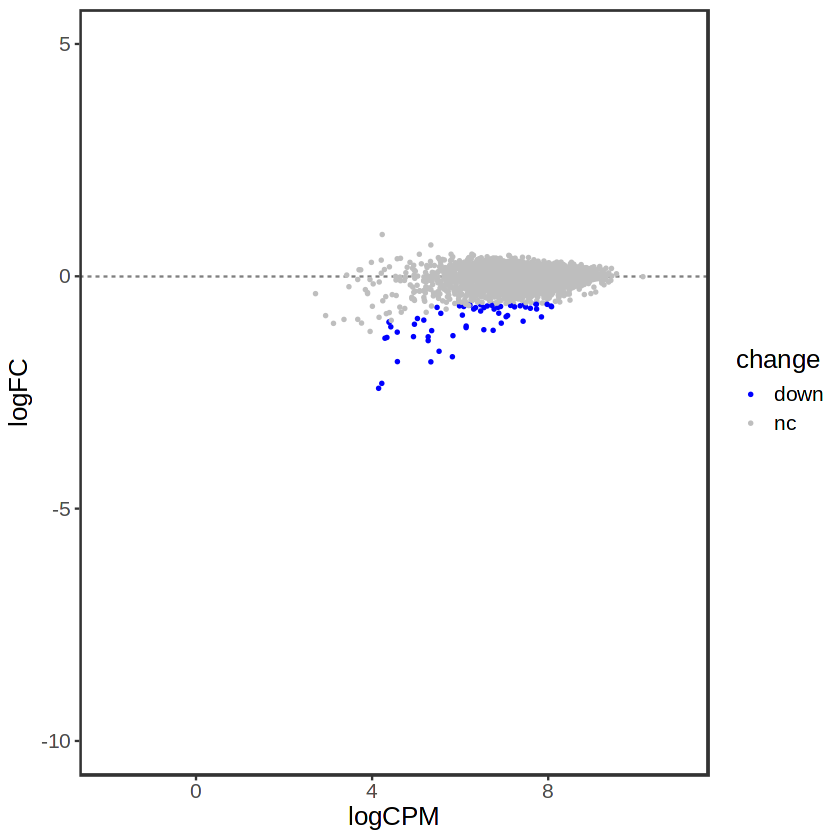

In [19]:
#MA plots for the above analyses

#res_control %>% ggplot(aes(x=logFC,y=-log10(FDR))) + geom_point(shape=21,aes(fill=change)) + scale_fill_manual(values=c("nc"="grey", "down"="blue", "up"="red"))  geom_vline(xintercept=c(-1,1)) + geom_hline(yintercept=-log10(.05))
res_norm %>% ggplot(aes(y=logFC,x=logCPM))  + geom_hline(yintercept=0,linetype=2, color="grey50") + geom_point(aes(color=change), size=.5) + scale_color_manual(values=c("nc"="grey", "down"="blue", "up"="red")) + ylim(-10,5) + xlim(-2,11)
res %>% ggplot(aes(y=logFC,x=logCPM))  + geom_hline(yintercept=0,linetype=2, color="grey50") + geom_point(aes(color=change), size=.5) + scale_color_manual(values=c("nc"="grey", "down"="blue", "up"="red")) + ylim(-10,5) + xlim(-2,11)
res_control %>% ggplot(aes(y=logFC,x=logCPM))  + geom_hline(yintercept=0,linetype=2, color="grey50") + geom_point(aes(color=change), size=.5) + scale_color_manual(values=c("nc"="grey", "down"="blue", "up"="red")) + ylim(-10,5) + xlim(-2,11)


`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.


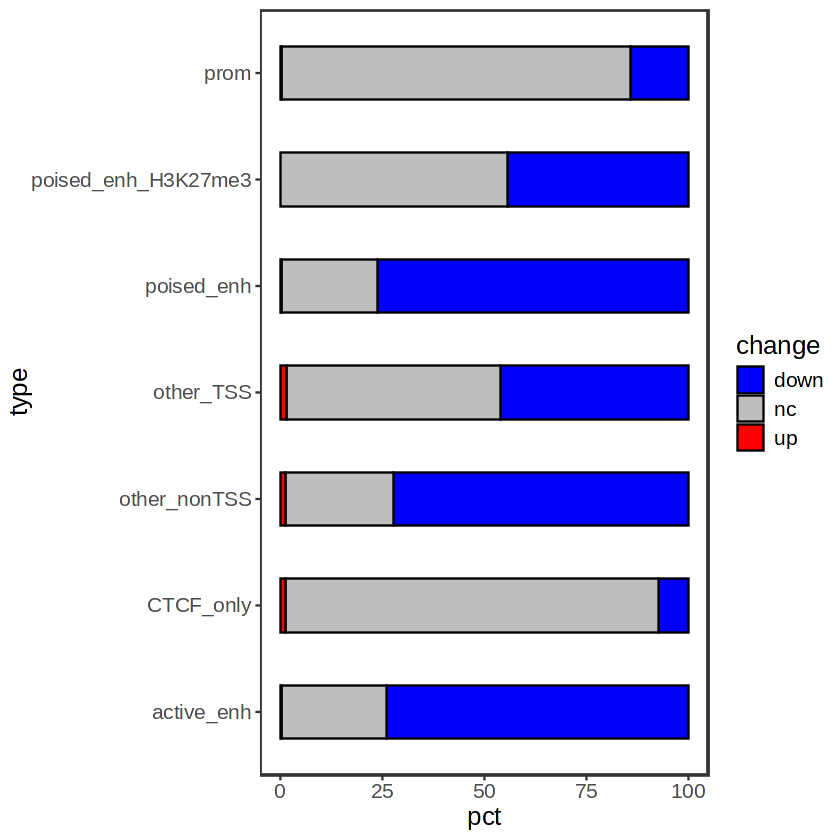

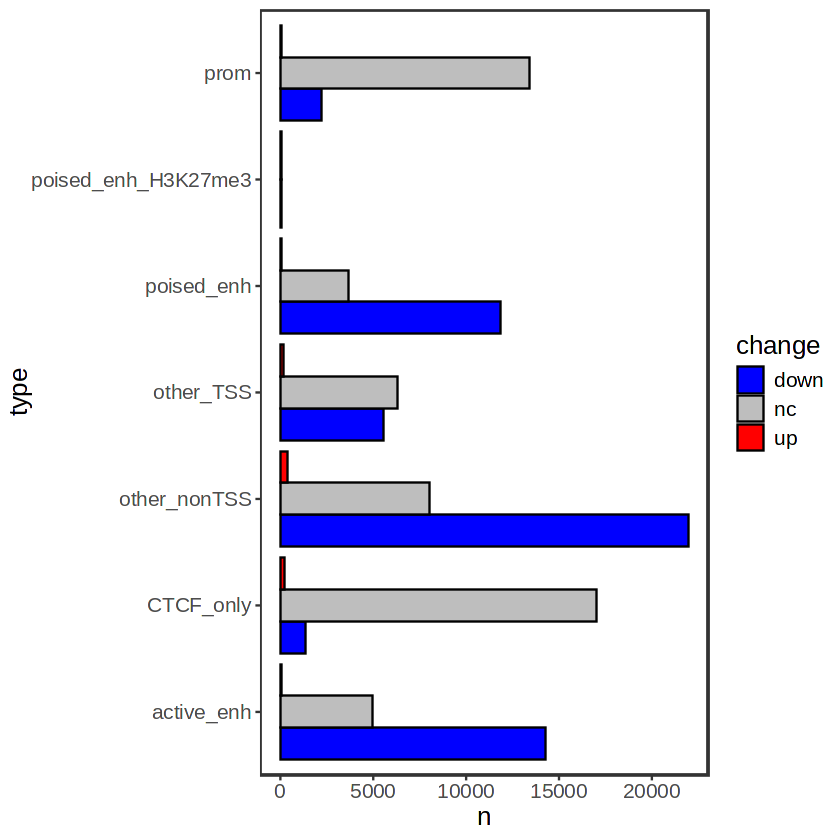

In [20]:
#looking at proportions of cRE types categorized by response to BAFinh 

res_norm %>% group_by(type=consensus_annot$type, change) %>% summarize(n=n()) %>% ungroup() %>% group_by(type) %>% summarize(change, n, pct=100*n/sum(n)) %>% 
    ggplot(aes(y=type, x=pct, fill=change)) + geom_col(color="black", width=.5) + scale_fill_manual(values=c("nc"="grey", "down"="blue", "up"="red"))

res_norm %>% group_by(type=consensus_annot$type, change) %>% summarize(n=n()) %>% ungroup() %>% group_by(type) %>% summarize(change, n, pct=100*n/sum(n)) %>% 
    ggplot(aes(y=type, x=n, fill=change)) + geom_col(color="black", position=position_dodge()) + scale_fill_manual(values=c("nc"="grey", "down"="blue", "up"="red"))

In [8]:
#Running DAR analysis with separate analysis of TSS-proximal and distal regiosn

res_splitTSS <- dar_splitTSS(counts, coldata, rowdata = consensus_annot)

In [31]:
#Summarizing results
res_splitTSS$results %>% group_by(change) %>% summarize(n())

#writing out table with row metadata, FC in accessibility due to BAFinh, associated FDR, and Boolean value for BAF dependence
BAFdep_summary <- res_splitTSS$row_meta %>% mutate(logFC=res_splitTSS$results$logFC, FDR=res_splitTSS$results$FDR) %>% mutate(BAFdep=case_when(logFC < -log2(1.5) & FDR < .05 ~ TRUE, TRUE ~ FALSE))
write.table(BAFdep_summary, file="/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/filtered/consensus_filt_annot_dar.tsv", sep='\t', col.names=T,row.names=F, quote=F)


change,n()
<chr>,<int>
down,57560
nc,53202
up,959


`summarise()` has grouped output by 'BAFdep'. You can override using the
`.groups` argument.


BAFdep,type,n()
<lgl>,<chr>,<int>
FALSE,CTCF_only,17188
FALSE,active_enh,4925
FALSE,other_TSS,6776
FALSE,other_nonTSS,8103
FALSE,poised_enh,3587
FALSE,poised_enh_H3K27me3,83
FALSE,prom,13499
TRUE,CTCF_only,1423
TRUE,active_enh,14420


In [43]:
#non-TSS and TSS regions will be analyzed separately
#starting with TSS-distal peaks

#subset countmat to only include TSS-distal regions
countmat_nonTSS <- countmat[consensus_annot$TSS==FALSE,]
#generate DGEList object
dge <- DGEList(counts=countmat_nonTSS[,5:10], group=c("dmso", "dmso", "dmso", "brm","brm","brm"))
dge <- calcNormFactors(dge)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge$samples)
dge <- estimateDisp(dge, design)

#this is the key step for normalization, where the default normalization factors are substituted for normalization factors generated using custom library sizes
dge$samples$norm.factors <- 1/calcNormFactors(as.matrix(dge), lib.size=sizes)

#run DAR analysis
dge_fit <- glmQLFit(dge)
diff <- glmQLFTest(dge_fit, contrast=c(1,-1))

#add differential accessibility stats (log2FC, FDR) to annotated peak data frame. Also including a boolean value for "BAF-dependence" (TRUE if FDR < .05 and log2FC < -log2(1.5) - note that this can be derived independently from the prior two values
consensus_annot_nonTSS <- consensus_annot[consensus_annot$TSS==FALSE,]
consensus_annot_nonTSS$logFC <- topTags(diff, n=Inf, sort.by="none")$table$logFC
consensus_annot_nonTSS$FDR <- topTags(diff, n=Inf, sort.by="none")$table$FDR
consensus_annot_nonTSS$BAFdep <- if_else(consensus_annot_nonTSS$logFC < log2((1/1.5)) & consensus_annot_nonTSS$FDR < .05, TRUE, FALSE)

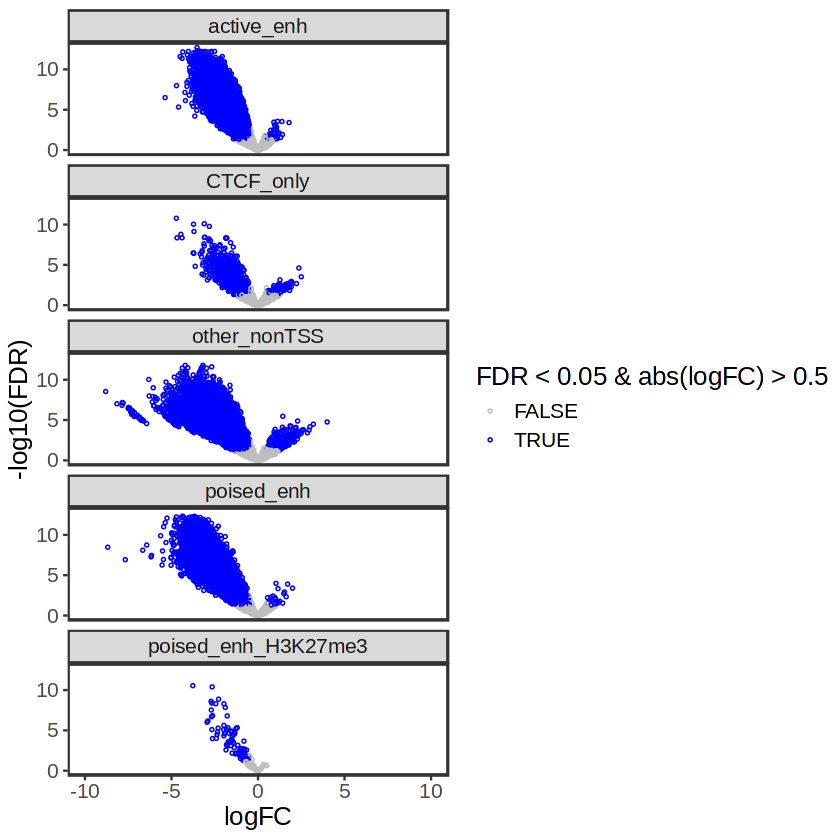

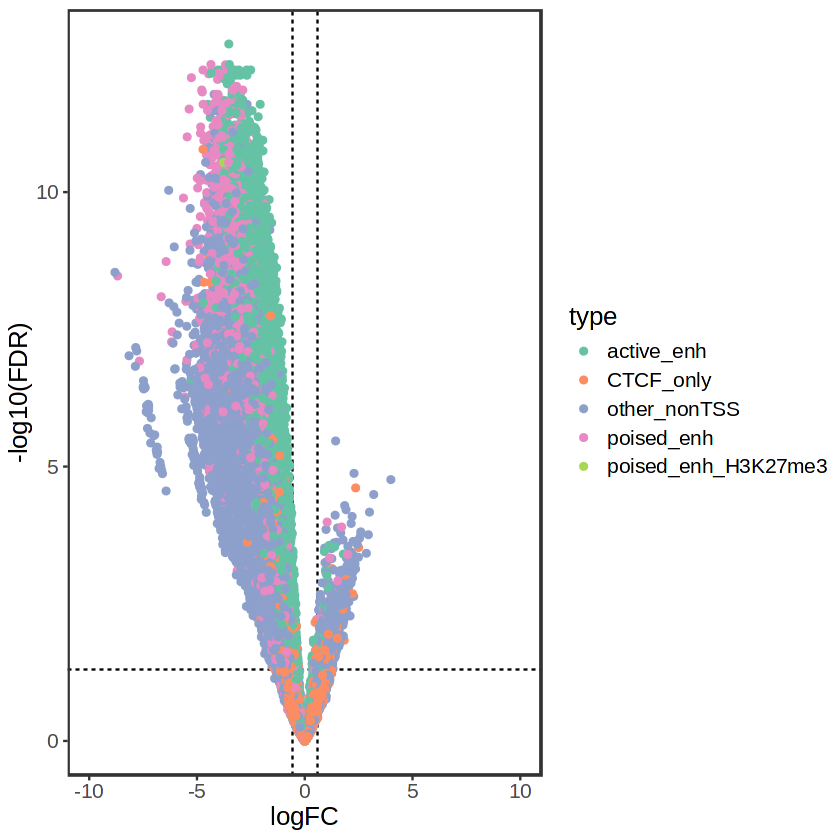

In [47]:
topTags(diff, n=Inf, sort.by="none")$table %>% mutate(type=consensus_annot[consensus_annot$TSS==FALSE,]$type) %>% 
    ggplot(aes(x=logFC,y=-log10(FDR))) + 
        geom_point(shape=21, aes(color=FDR < .05 & abs(logFC) > .5),size=.5) + 
        scale_color_manual(values=c("grey", "blue")) + 
        facet_wrap(~type, ncol=1) + 
        xlim(-10,10)

topTags(diff, n=Inf, sort.by="none")$table %>% mutate(type=consensus_annot[consensus_annot$TSS==FALSE,]$type) %>% 
    ggplot(aes(x=logFC,y=-log10(FDR))) + 
        geom_hline(yintercept=-log10(.05), linetype=2) + geom_vline(xintercept=c(-.58,.58), linetype=2) + 
        geom_point(aes(color=type)) + scale_color_brewer(palette="Set2") + xlim(-10,10) 

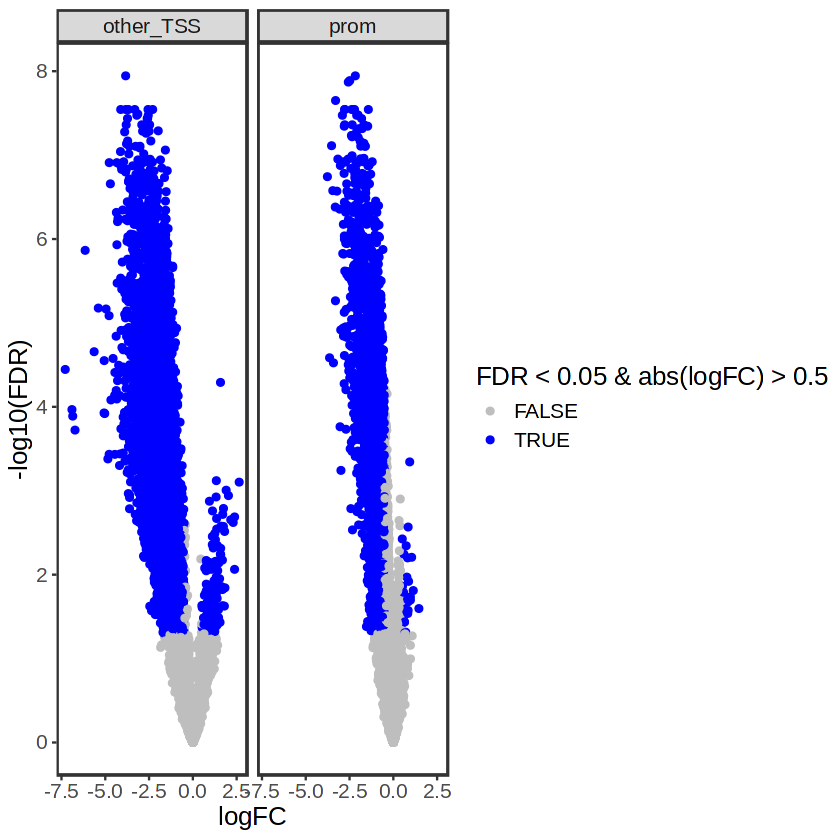

In [48]:
#similarly for TSS peaks

#subset countmat to only include TSS-proximal regions
countmat_TSS <- countmat[consensus_annot$TSS==TRUE,]
#generate DGEList object
dge <- DGEList(counts=countmat_TSS[,5:10], group=c("dmso", "dmso", "dmso", "brm","brm","brm"))
dge <- calcNormFactors(dge)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge$samples)
dge <- estimateDisp(dge, design)

#custom normalization factors
dge$samples$norm.factors <- 1/calcNormFactors(as.matrix(dge), lib.size=sizes)

#run DAR analysis
dge_fit <- glmQLFit(dge)
diff <- glmQLFTest(dge_fit, contrast=c(1,-1))

topTags(diff, n=Inf, sort.by="none")$table %>% mutate(type=consensus_annot[consensus_annot$TSS==TRUE,]$type) %>% ggplot(aes(x=logFC,y=-log10(FDR))) + geom_point(aes(color=FDR < .05 & abs(logFC) > .5)) + scale_color_manual(values=c("grey", "blue")) + facet_wrap(~type)

consensus_annot_TSS <- consensus_annot[consensus_annot$TSS==TRUE,]
consensus_annot_TSS$logFC <- topTags(diff, n=Inf, sort.by="none")$table$logFC
consensus_annot_TSS$FDR <- topTags(diff, n=Inf, sort.by="none")$table$FDR
consensus_annot_TSS$BAFdep <- if_else(consensus_annot_TSS$logFC < log2((1/1.5)) & consensus_annot_TSS$FDR < .05, TRUE, FALSE)

In [49]:
#remake table with both TSS and nonTSS
consensus_annot_dar <- rbind(consensus_annot_TSS, consensus_annot_nonTSS)
write.table(consensus_annot_dar, file="/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/filtered/consensus_filt_annot_dar.tsv", sep='\t', col.names=T,row.names=F, quote=F)


Saving 14 x 7 in image
`summarise()` has grouped output by 'change'. You can override using the
`.groups` argument.


change,TSS,n()
<chr>,<lgl>,<int>
down,FALSE,52627
down,TRUE,8069
nc,FALSE,31209
nc,TRUE,19520
up,FALSE,807
up,TRUE,172


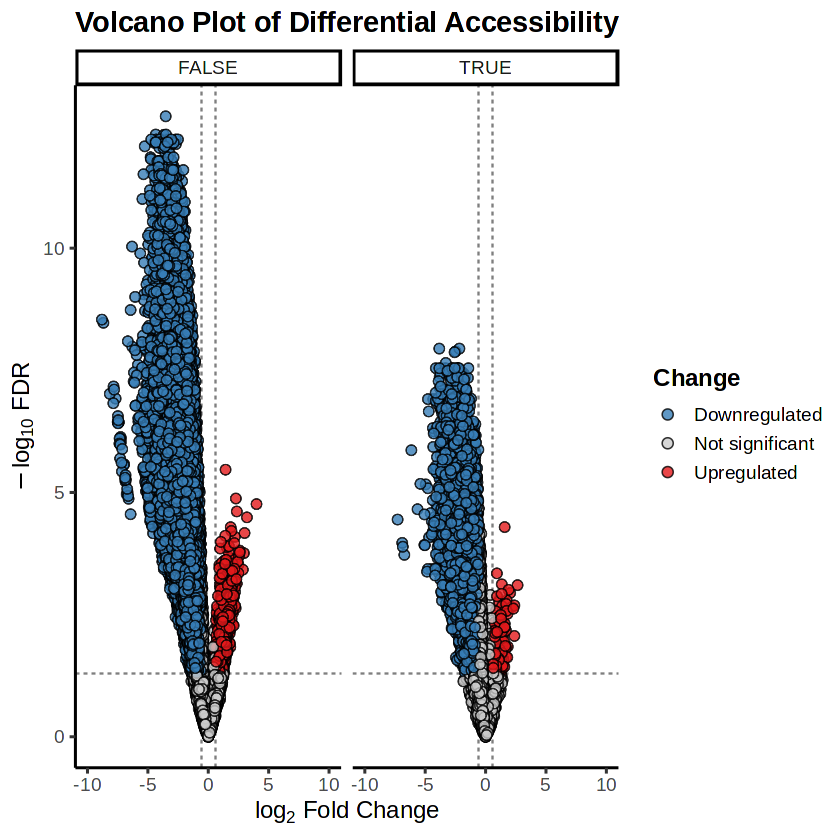

In [106]:
# Refined volcano plot
library(RColorBrewer)
library(ggrastr)

consensus_annot_dar %>%
  mutate(
    change = case_when(
      FDR < 0.05 & logFC > log2(1.5) ~ "up",
      FDR < 0.05 & logFC < -log2(1.5) ~ "down",
      TRUE ~ "nc"
    )
  ) %>%
  ggplot(aes(x = logFC, y = -log10(FDR), fill = change)) +
  geom_vline(xintercept = c(-log2(1.5), log2(1.5)), linetype = "dashed", color = "grey50") +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "grey50") +
  rasterize(geom_point(shape = 21, size = 2.5, color = "black", alpha = 0.8), dpi=300) +
  scale_fill_manual(
    values = c("up" = brewer.pal(3, "Set1")[1], "down" = brewer.pal(3, "Set1")[2], "nc" = "grey80"),
    #values = c("up" = "black", "down" = "darkred", "nc" = "lightgrey"),
    labels = c("nc" = "Not significant", "up" = "Upregulated", "down" = "Downregulated"),
    name = "Change"
  ) +
  labs(
    title = "Volcano Plot of Differential Accessibility",
    x = expression(log[2] ~ "Fold Change"),
    y = expression(-log[10] ~ "FDR")
  ) +
  xlim(-10,10) +  # Adjust for your actual range
  theme_classic(base_size = 14) +
  theme(
    legend.position = "right",
    legend.title = element_text(face = "bold"),
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.title = element_text(face = "bold")
  ) +
facet_wrap(~TSS)
ggsave("~/projects/poised_enh_manuscript/scratch/temp_plots/volcano_all_2.pdf", width=14)

consensus_annot_dar %>%
  mutate(
    change = case_when(
      FDR < 0.05 & logFC > log2(1.5) ~ "up",
      FDR < 0.05 & logFC < -log2(1.5) ~ "down",
      TRUE ~ "nc"
    )) %>%
      group_by(change, TSS) %>% summarize(n())

Saving 8 x 7 in image
`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


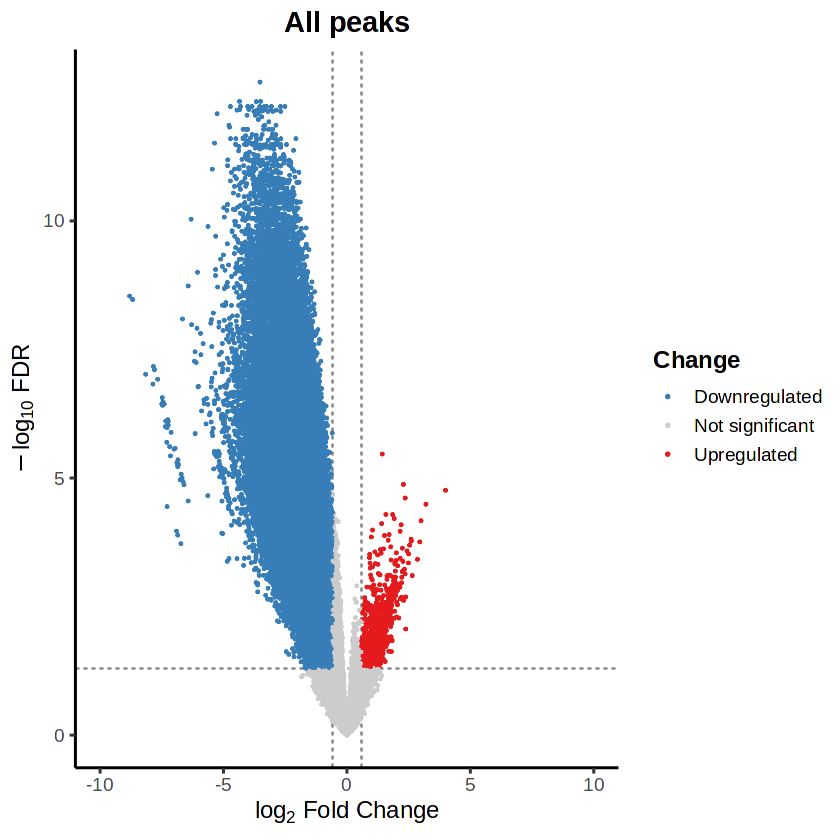

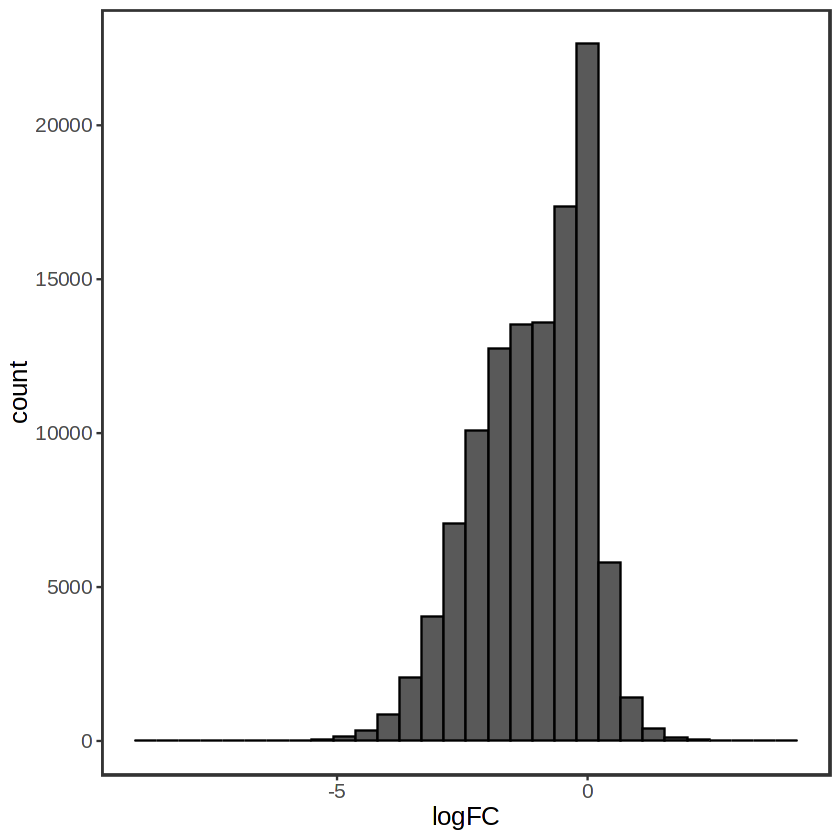

In [247]:
consensus_annot_dar %>%
  mutate(
    change = case_when(
      FDR < 0.05 & logFC > log2(1.5) ~ "up",
      FDR < 0.05 & logFC < -log2(1.5) ~ "down",
      TRUE ~ "nc"
    )
  ) %>%
  ggplot(aes(x = logFC, y = -log10(FDR), color = change)) +
  geom_vline(xintercept = c(-log2(1.5), log2(1.5)), linetype = "dashed", color = "grey50") +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "grey50") +
  rasterize(geom_point(size = .5, alpha = 1), dpi=300) +
  scale_color_manual(
    values = c("up" = brewer.pal(3, "Set1")[1], "down" = brewer.pal(3, "Set1")[2], "nc" = "grey80"),
    #values = c("up" = "black", "down" = "darkred", "nc" = "lightgrey"),
    labels = c("nc" = "Not significant", "up" = "Upregulated", "down" = "Downregulated"),
    name = "Change"
  ) +
  labs(
    title = "All peaks",
    x = expression(log[2] ~ "Fold Change"),
    y = expression(-log[10] ~ "FDR")
  ) +
  xlim(-10,10) +  # Adjust for your actual range
  theme_classic(base_size = 14) +
  theme(
    legend.position = "right",
    legend.title = element_text(face = "bold"),
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.title = element_text(face = "bold")
  )
ggsave("~/projects/poised_enh_manuscript/scratch/temp_plots/volcano_all_2.pdf", width=8)



Saving 7 x 2 in image


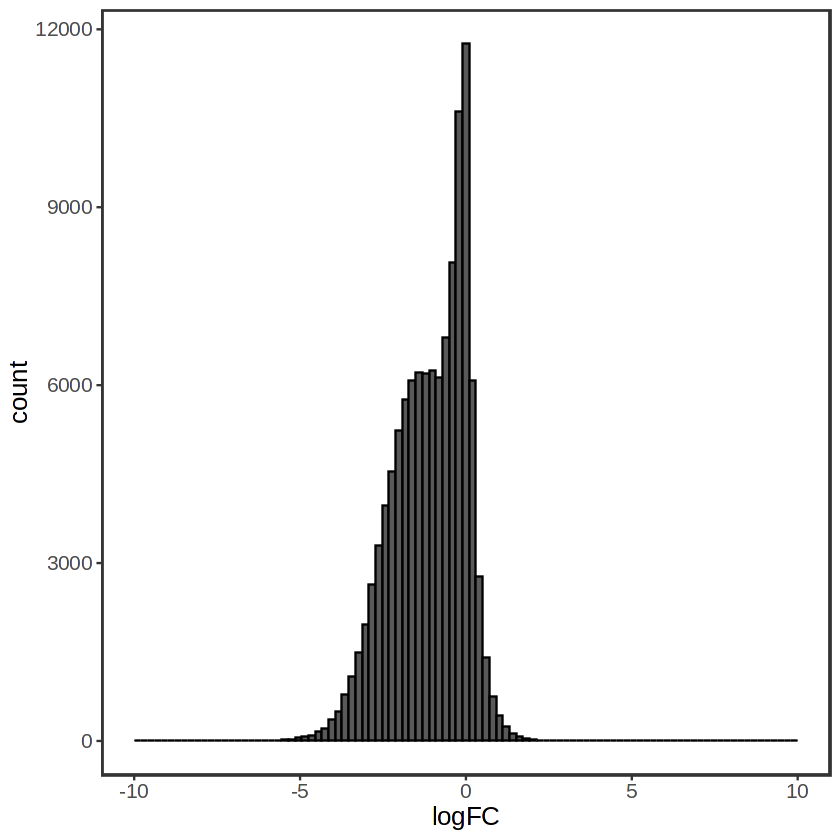

In [251]:
consensus_annot_dar %>% ggplot(aes(x=logFC)) + geom_histogram(color="black", bins=100) + xlim(-10,10)
ggsave("~/projects/poised_enh_manuscript/scratch/temp_plots/all_peaks_hist.pdf", height=2)

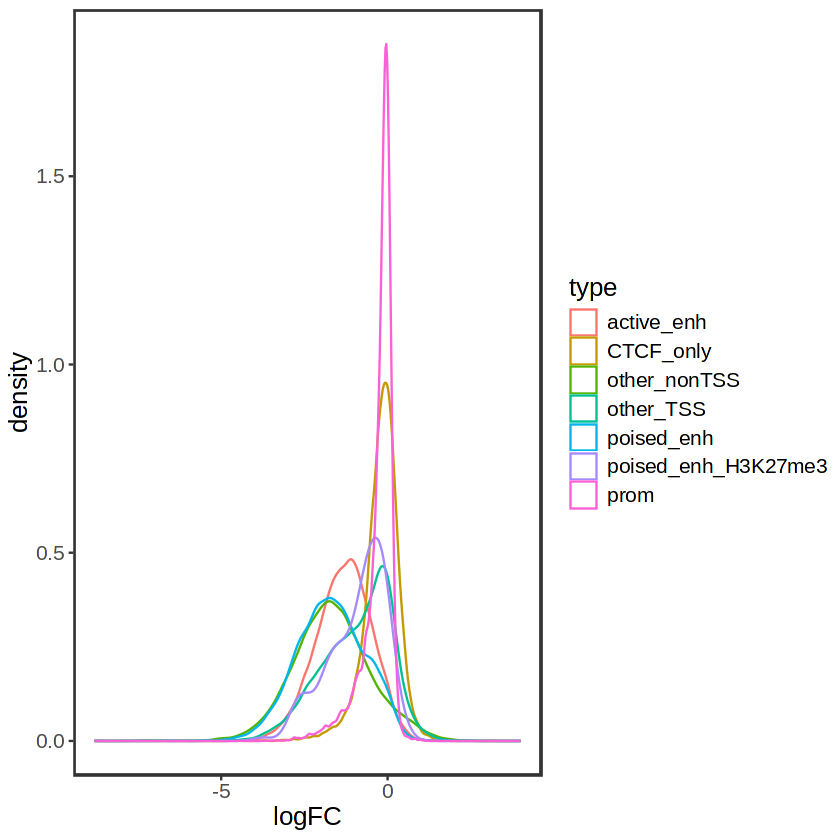

In [242]:
consensus_annot_dar %>% ggplot(aes(x=logFC)) + geom_density(aes(color=type))

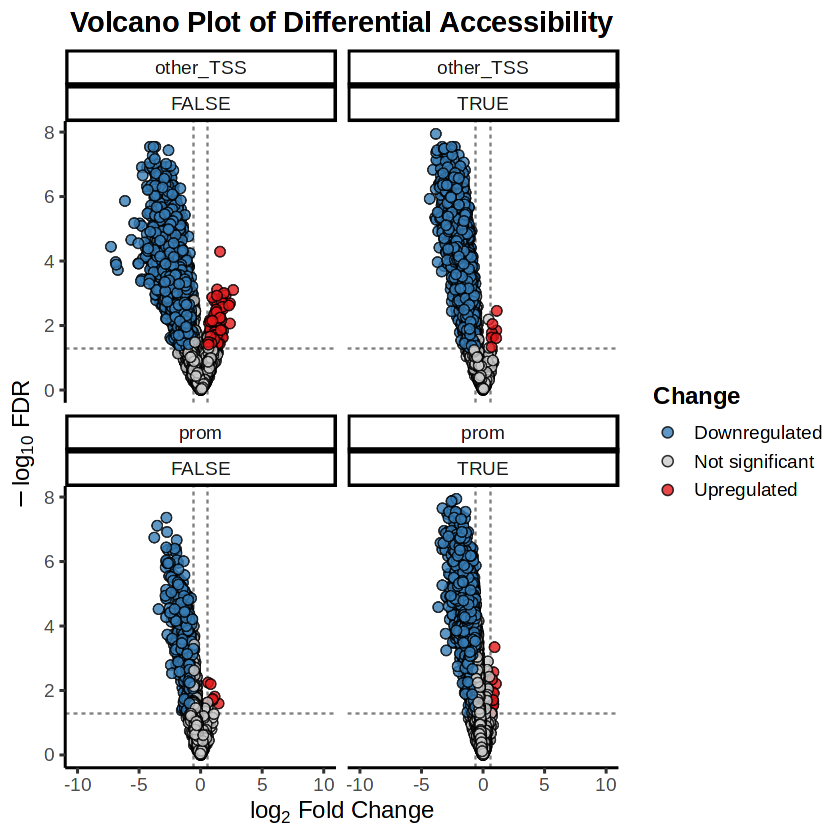

In [157]:
consensus_annot_dar %>% filter(TSS == TRUE) %>% 
  mutate(
    change = case_when(
      FDR < 0.05 & logFC > log2(1.5) ~ "up",
      FDR < 0.05 & logFC < -log2(1.5) ~ "down",
      TRUE ~ "nc"
    )
  ) %>%
  ggplot(aes(x = logFC, y = -log10(FDR), fill = change)) +
  geom_vline(xintercept = c(-log2(1.5), log2(1.5)), linetype = "dashed", color = "grey50") +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "grey50") +
  rasterize(geom_point(shape = 21, size = 2.5, color = "black", alpha = 0.8), dpi=300) +
  scale_fill_manual(
    values = c("up" = brewer.pal(3, "Set1")[1], "down" = brewer.pal(3, "Set1")[2], "nc" = "grey80"),
    #values = c("up" = "black", "down" = "darkred", "nc" = "lightgrey"),
    labels = c("nc" = "Not significant", "up" = "Upregulated", "down" = "Downregulated"),
    name = "Change"
  ) +
  labs(
    title = "Volcano Plot of Differential Accessibility",
    x = expression(log[2] ~ "Fold Change"),
    y = expression(-log[10] ~ "FDR")
  ) +
  xlim(-10,10) +  # Adjust for your actual range
  theme_classic(base_size = 14) +
  theme(
    legend.position = "right",
    legend.title = element_text(face = "bold"),
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.title = element_text(face = "bold")
  ) +
facet_wrap(~type+H3K27ac)

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
Saving 7 x 4 in image


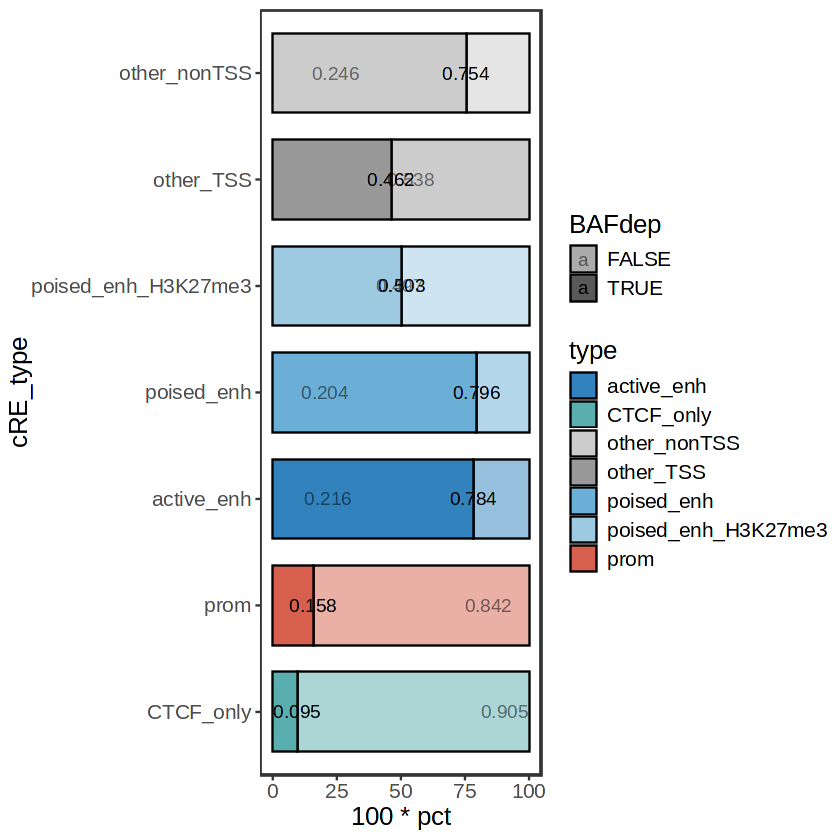

In [212]:
consensus_annot_dar %>% group_by(type, BAFdep) %>% summarize(count=n()) %>% ungroup() %>% group_by(type) %>% summarize(BAFdep, count, pct=count/sum(count)) %>% ggplot(aes(y=factor(type, levels=order),x=100*pct, fill=type, alpha=BAFdep)) + geom_col(color="black", width=.75) + 
scale_fill_manual(
  values = c(
    "CTCF_only" = "#5AAEAE",           # muted teal
    "prom" = "#D6604D",                # muted red
    "active_enh" = "#3182BD",          # deep blue
    "poised_enh" = "#6BAED6",          # medium blue
    "poised_enh_H3K27me3" = "#9ECAE1", # light blue
    "other_TSS" = "#999999",           # gray
    "other_nonTSS" = "#CCCCCC"         # light gray
  )
) + ylab("cRE_type") + scale_alpha_manual(values=c(0.5,1)) + geom_text(aes(label=round(pct, digits=3)))
ggsave("~/projects/poised_enh_manuscript/scratch/temp_plots/colplot_cREs_BAFdep.pdf", height=4)

`summarise()` has grouped output by 'H3K27ac'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'H3K27ac'. You can override using the
`.groups` argument.


H3K27ac,BAFdep,count,pct
<lgl>,<lgl>,<int>,<dbl>
FALSE,FALSE,2417,0.7890957
FALSE,TRUE,646,0.2109043
TRUE,FALSE,10763,0.8544098
TRUE,TRUE,1834,0.1455902


`summarise()` has grouped output by 'H3K27ac'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'H3K27ac'. You can override using the
`.groups` argument.


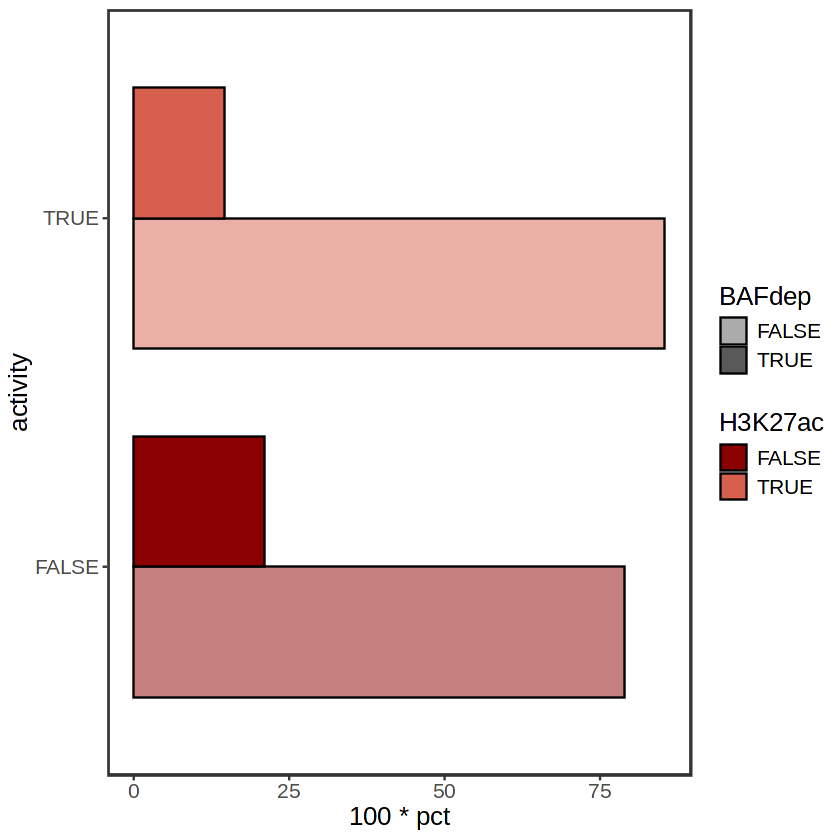

In [216]:
consensus_annot_dar %>% filter(type == "prom") %>% group_by(H3K27ac, BAFdep) %>% summarize(count=n()) %>% ungroup() %>% group_by(H3K27ac) %>% summarize(BAFdep, count, pct=count/sum(count))
consensus_annot_dar %>% filter(type == "prom") %>% group_by(H3K27ac, BAFdep) %>% summarize(count=n()) %>% ungroup() %>% group_by(H3K27ac) %>% summarize(BAFdep, count, pct=count/sum(count)) %>% ggplot(aes(y=H3K27ac,x=100*pct, fill=H3K27ac, alpha=BAFdep)) + geom_col(color="black", width=.75, position=position_dodge()) + 
ylab("activity") + scale_alpha_manual(values=c(0.5,1)) + scale_fill_manual(values=c("darkred", "#D6604D"))
ggsave("~/projects/poised_enh_manuscript/scratch/temp_plots/colplot_prom_BAFdep.pdf", height=3, width=4)

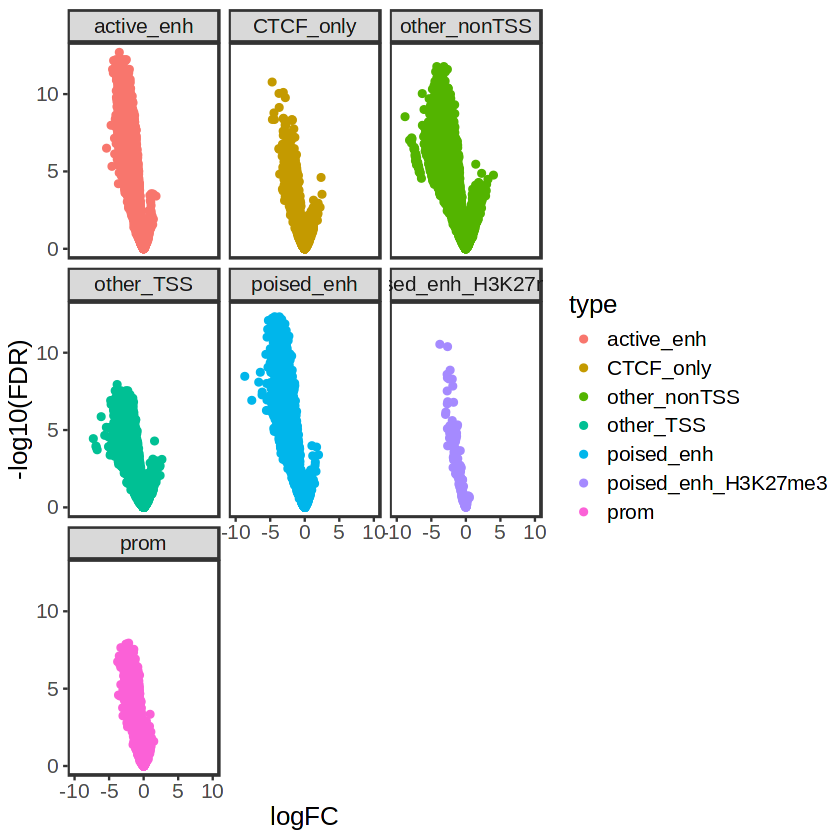

Saving 7 x 4 in image


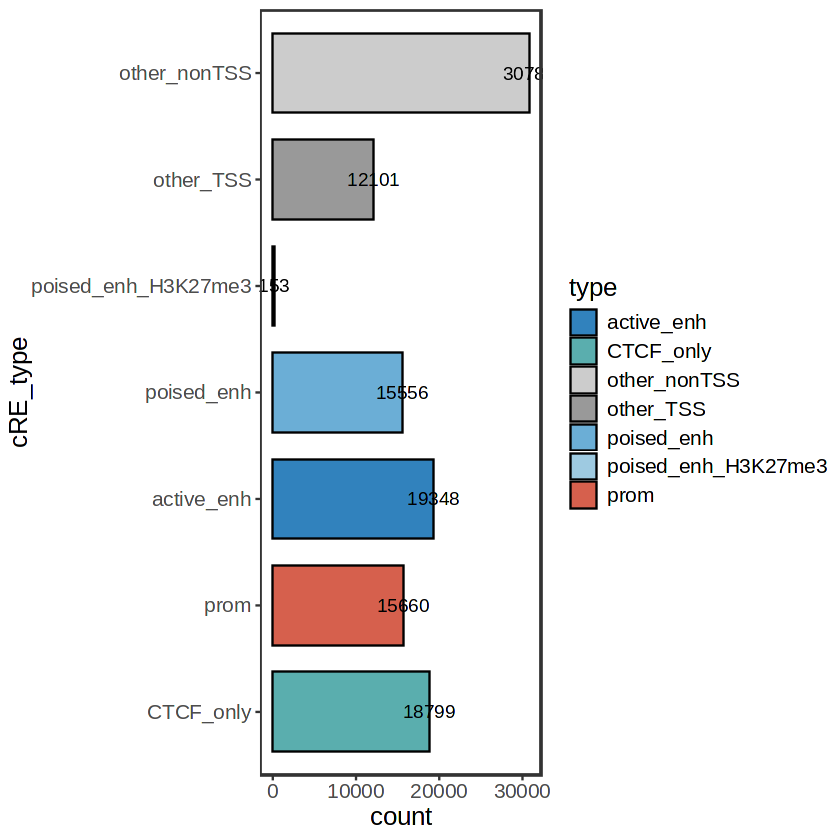

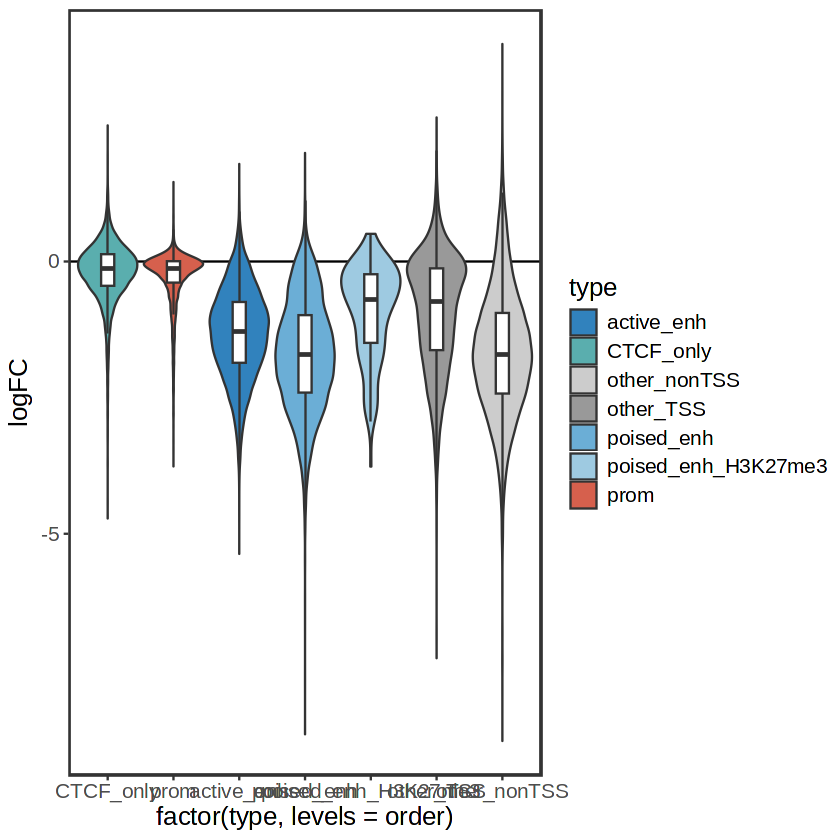

Saving 7 x 7 in image


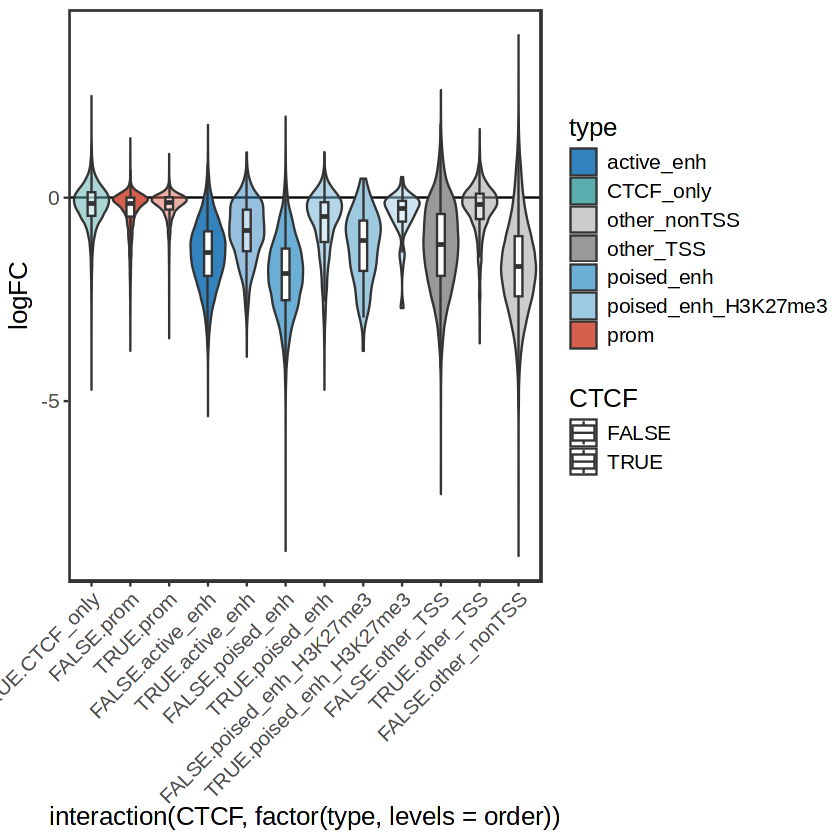

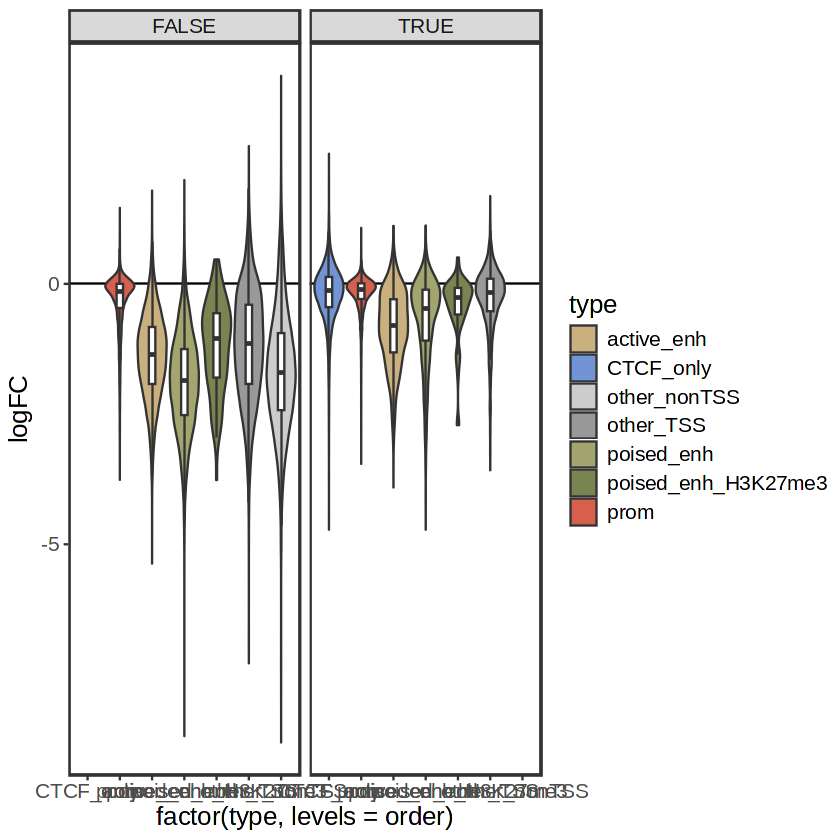

In [192]:


consensus_annot_dar %>% ggplot(aes(x=logFC, y=-log10(FDR))) + geom_point(aes(color=type)) + facet_wrap(~type) + xlim(-10,10)
order <- c("CTCF_only", "prom", "active_enh", "poised_enh", "poised_enh_H3K27me3", "other_TSS", "other_nonTSS")

consensus_annot_dar %>% group_by(type) %>% summarize(count=n()) %>% ggplot(aes(y=factor(type, levels=order),x=count, fill=type)) + geom_col(color="black", width=.75) + 
scale_fill_manual(
  values = c(
    "CTCF_only" = "#5AAEAE",           # muted teal
    "prom" = "#D6604D",                # muted red
    "active_enh" = "#3182BD",          # deep blue
    "poised_enh" = "#6BAED6",          # medium blue
    "poised_enh_H3K27me3" = "#9ECAE1", # light blue
    "other_TSS" = "#999999",           # gray
    "other_nonTSS" = "#CCCCCC"         # light gray
  )
) + ylab("cRE_type") + geom_text(aes(label=count))
ggsave("~/projects/poised_enh_manuscript/scratch/temp_plots/colplot_n_cREs.pdf", height=4)

consensus_annot_dar %>% group_by(type, BAFdep) %>% summarize(count=n()) %>% ungroup() %>% group_by(type) %>% summarize(BAFdep, count, pct=count/sum(count)) %>% ggplot(aes(y=factor(type, levels=order),x=pct, fill=BAFdep)) + geom_col(color="black", width=.75) + 
scale_fill_manual(
  values = c(
    "CTCF_only" = "#5AAEAE",           # muted teal
    "prom" = "#D6604D",                # muted red
    "active_enh" = "#3182BD",          # deep blue
    "poised_enh" = "#6BAED6",          # medium blue
    "poised_enh_H3K27me3" = "#9ECAE1", # light blue
    "other_TSS" = "#999999",           # gray
    "other_nonTSS" = "#CCCCCC"         # light gray
  )
) + ylab("cRE_type") + geom_text(aes(label=count))

consensus_annot_dar %>% 
    ggplot(aes(x=factor(type, levels=order),y=logFC, fill=type)) + 
        geom_hline(yintercept=0) + 
        geom_violin(scale="width") + 
        geom_boxplot(fill="white", width=.2, outlier.shape=NA) +
scale_fill_manual(
  values = c(
    "CTCF_only" = "#5AAEAE",           # muted teal
    "prom" = "#D6604D",                # muted red
    "active_enh" = "#3182BD",          # deep blue
    "poised_enh" = "#6BAED6",          # medium blue
    "poised_enh_H3K27me3" = "#9ECAE1", # light blue
    "other_TSS" = "#999999",           # gray
    "other_nonTSS" = "#CCCCCC"         # light gray
  )
)

consensus_annot_dar %>% 
    ggplot(aes(x=interaction(CTCF, factor(type, levels=order)),y=logFC, fill=type, alpha=CTCF)) + 
        geom_hline(yintercept=0) + 
        geom_violin(scale="width") + 
        geom_boxplot(fill="white", width=.2, outlier.shape=NA) + 
        scale_fill_manual(
  values = c(
    "CTCF_only" = "#5AAEAE",           # muted teal
    "prom" = "#D6604D",                # muted red
    "active_enh" = "#3182BD",          # deep blue
    "poised_enh" = "#6BAED6",          # medium blue
    "poised_enh_H3K27me3" = "#9ECAE1", # light blue
    "other_TSS" = "#999999",           # gray
    "other_nonTSS" = "#CCCCCC"         # light gray
  )
) + scale_alpha_manual(values=c(1,.5)) + theme(axis.text.x=element_text(angle=45, hjust=1))
ggsave("~/projects/poised_enh_manuscript/scratch/temp_plots/violin_byCTCF.pdf")


consensus_annot_dar %>% 
    ggplot(aes(x=factor(type, levels=order),y=logFC, fill=type)) + 
        geom_hline(yintercept=0) + 
        geom_violin(scale="width") + 
        geom_boxplot(fill="white", width=.2, outlier.shape=NA) + facet_wrap(~CTCF) +
   scale_fill_manual(
  values = c(
    "CTCF_only" = "#7294D4",
    "prom" = "#D6604D",
    "active_enh" = "#CAAF7F",
    "poised_enh" = "#A3A56F",
    "poised_enh_H3K27me3" = "#7A8450",
    "other_TSS" = "#999999",
    "other_nonTSS" = "#CCCCCC"
  )
)

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
Saving 7 x 7 in image


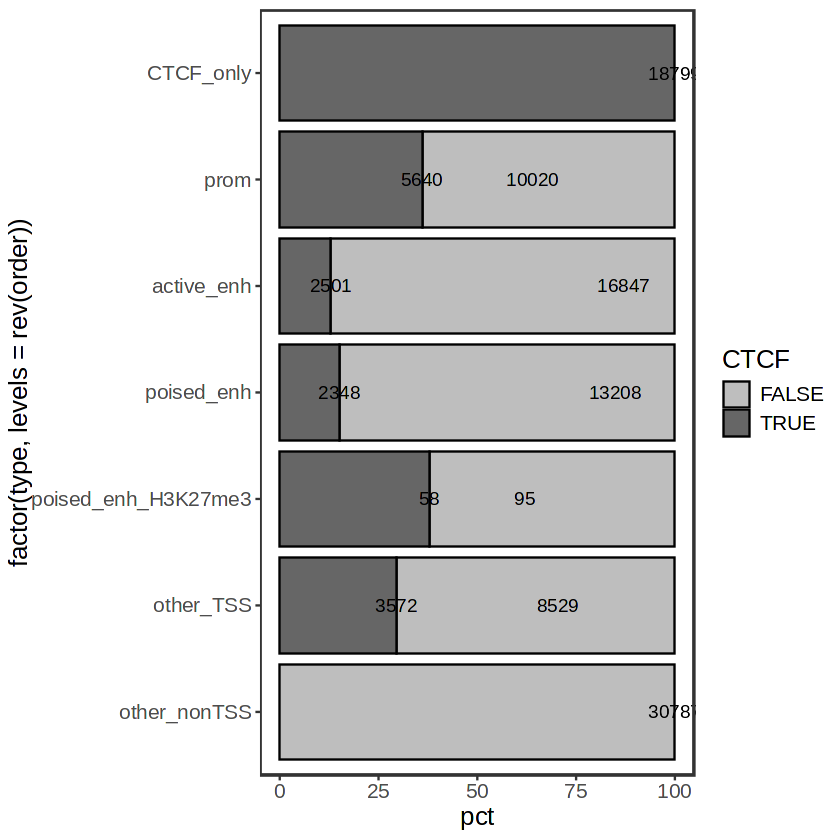

In [176]:
consensus_annot_dar %>% group_by(type, CTCF) %>% summarize(count=n()) %>% ungroup() %>% group_by(type) %>% summarize(CTCF, count, pct=100*count/sum(count)) %>% 
    ggplot(aes(y=factor(type,levels=rev(order)), x=pct, fill=CTCF)) + geom_col(color="black") + geom_text(aes(label=count)) + scale_fill_manual(values=c("grey", "#666666"))
ggsave("~/projects/poised_enh_manuscript/scratch/temp_plots/proportion_CTCF.pdf")

Saving 7 x 7 in image


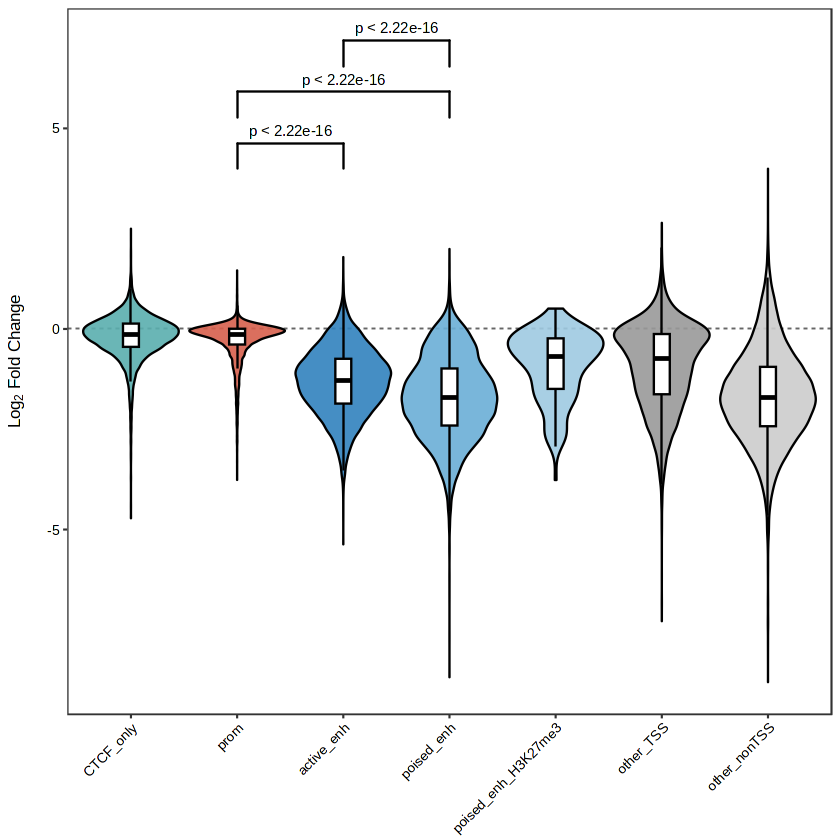

In [136]:
#install.packages("ggsignif")  # if not already installed
library(ggsignif)

consensus_annot_dar %>%
  ggplot(aes(x = factor(type, levels = order), y = logFC, fill = type)) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "gray40", size = 0.4) +
    geom_violin(scale = "width", trim = TRUE, color = "black", alpha = 0.9) +
    geom_boxplot(width = 0.15, fill = "white", color = "black", outlier.shape = NA) +
    scale_fill_manual(
      values = c(
        "CTCF_only" = "#5AAEAE",
        "prom" = "#D6604D",
        "active_enh" = "#3182BD",
        "poised_enh" = "#6BAED6",
        "poised_enh_H3K27me3" = "#9ECAE1",
        "other_TSS" = "#999999",
        "other_nonTSS" = "#CCCCCC"
      )
    ) +
    labs(
      x = NULL,
      y = expression(Log[2]~Fold~Change),
      fill = NULL
    ) +
    theme_bw(base_size = 10) +
    theme(
      axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1, color = "black"),
      axis.text.y = element_text(color = "black"),
      axis.title.y = element_text(margin = margin(r = 10)),
      panel.grid.major = element_blank(),
      panel.grid.minor = element_blank(),
      legend.position = "none",
      plot.title = element_text(face = "bold")
    ) +
    geom_signif(
      comparisons = list(c("prom", "active_enh"), c("prom", "poised_enh"), c("active_enh", "poised_enh")),
      map_signif_level = FALSE,  # shows stars by default
      test = "wilcox.test",          # or "wilcox.test"
      step_increase = 0.1,
      textsize = 3,
      tip_length = 0.05
)
ggsave("~/projects/poised_enh_manuscript/scratch/temp_plots/violin_all.pdf")

In [32]:
#run DAR analysis on control regions

dge2 <- DGEList(counts=countmat_control[,5:10], group=c("dmso", "dmso", "dmso", "brm","brm","brm"))
dge2 <- calcNormFactors(dge2)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge2$samples)
dge2 <- estimateDisp(dge2, design)

#this is the key step, where I am calculating normalization factors using the summed counts at invariant promoters as my library sizes
dge2$samples$norm.factors <- 1/calcNormFactors(as.matrix(dge2), lib.size=sizes)

#run DAR analysis
dge_fit2 <- glmQLFit(dge2)
diff2 <- glmQLFTest(dge_fit2, contrast=c(1,-1))

Scale for x is already present.
Adding another scale for x, which will replace the existing scale.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”


n,change,pct
<int>,<chr>,<dbl>
50,down,0.009924573
4988,nc,0.990075427


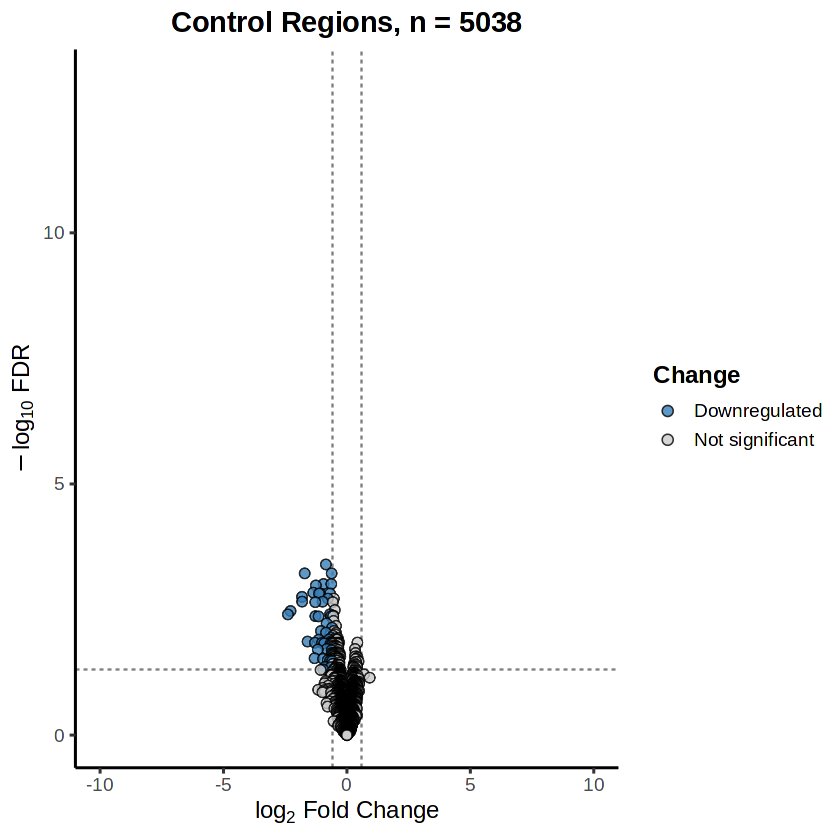

In [164]:
topTags(diff2, n=Inf)$table %>% mutate(
    change = case_when(
      FDR < 0.05 & logFC > log2(1.5) ~ "up",
      FDR < 0.05 & logFC < -log2(1.5) ~ "down",
      TRUE ~ "nc"
    )
  ) %>%
  ggplot(aes(x = logFC, y = -log10(FDR), fill = change)) +
  geom_vline(xintercept = c(-log2(1.5), log2(1.5)), linetype = "dashed", color = "grey50") +
  geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "grey50") +
  rasterize(geom_point(shape = 21, size = 2.5, color = "black", alpha = 0.8), dpi=300) +
  scale_fill_manual(
    values = c("up" = brewer.pal(3, "Set1")[1], "down" = brewer.pal(3, "Set1")[2], "nc" = "grey80"),
    #values = c("up" = "black", "down" = "darkred", "nc" = "lightgrey"),
    labels = c("nc" = "Not significant", "up" = "Upregulated", "down" = "Downregulated"),
    name = "Change"
  ) +
  labs(
    title = paste("Control Regions, n =", nrow(topTags(diff2, n=Inf)$table)),
    x = expression(log[2] ~ "Fold Change"),
    y = expression(-log[10] ~ "FDR")
  ) +
  xlim(-10,10) +  # Adjust for your actual range
  theme_classic(base_size = 14) +
  theme(
    legend.position = "right",
    legend.title = element_text(face = "bold"),
    plot.title = element_text(hjust = 0.5, face = "bold"),
    axis.title = element_text(face = "bold")
  ) + xlim(-10,10) + ylim(0,13)
topTags(diff2, n=Inf)$table %>% group_by(change = case_when(
      FDR < 0.05 & logFC > log2(1.5) ~ "up",
      FDR < 0.05 & logFC < -log2(1.5) ~ "down",
      TRUE ~ "nc")) %>% summarize(n=n(), lfc=mean(logFC)) %>% ungroup() %>% summarize(n,change,pct=n/sum(n))

In [5]:
dir_2 <- "/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/bigwig/ENCODE/GM12878/"
feats <- c("CHD4", "CTCF", "DPF2", "H3K27ac", "H3K27me3", "H3K4me1", "H3K4me3", "HDAC2")

In [15]:
consensus_annot <- read.delim("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/filtered/consensus_filt_annot.tsv") %>% select(!c(H3K4me3, CTCF, H3K27ac, H3K27me3)) %>% rename("H3K4me1"="H3K4me1_bed")

for(feat in feats){
    temp <- read.delim(paste0(dir_2,feat, ".tab"), sep='\t', header=F) %>% arrange(V1)
    consensus_annot[[feat]] <- temp$V5
}

In [7]:
library(pheatmap)
library(RColorBrewer)

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.


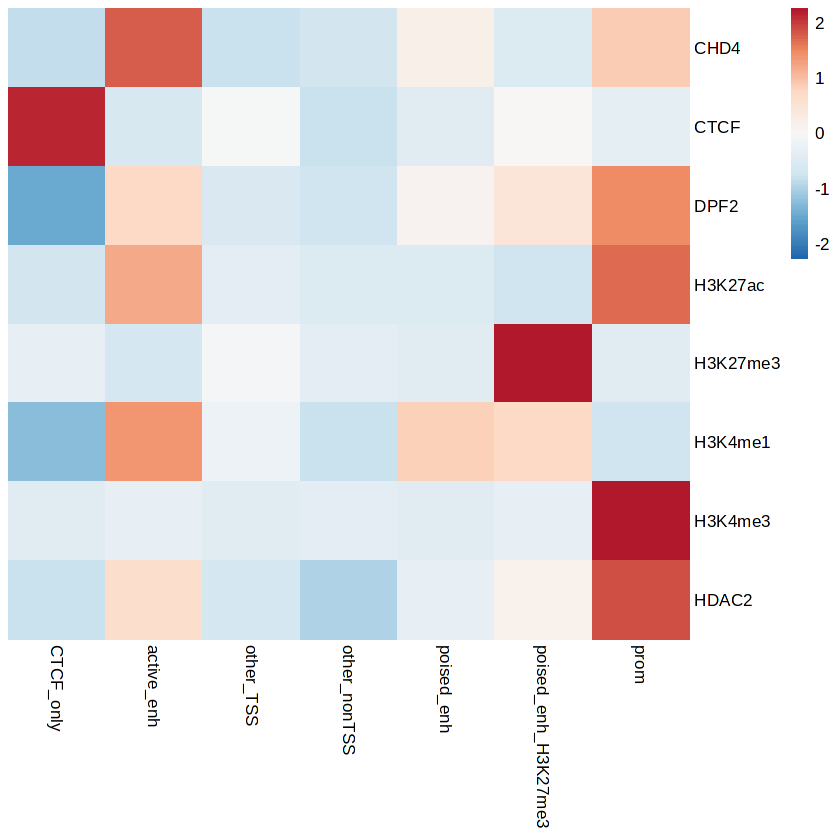

In [18]:
consensus_annot %>% select(type, CHD4, CTCF, DPF2, H3K27ac, H3K27me3, H3K4me1, H3K4me3, HDAC2) %>% pivot_longer(!type) %>% group_by(type, name) %>% 
    summarize(mean=mean(value)) %>% pivot_wider(names_from=name, values_from=mean) %>% column_to_rownames("type") %>% t()  %>% 
    pheatmap(color=colorRampPalette(colors=rev(brewer.pal(7, "RdBu")))(100), scale="row", border_color=NA,
            cluster_rows=FALSE, cluster_cols=FALSE)

#consensus_annot %>% pivot_longer(!type) %>% group_by(type, name) %>% 
#    summarize(mean=mean(value)) %>% pivot_wider(names_from=name, values_from=mean) %>% column_to_rownames("type") %>% t()  %>% 
#    pheatmap(color=colorRampPalette(colors=(brewer.pal(7, "Reds")))(100), border_color=NA, cluster_rows=FALSE, cluster_cols=FALSE,main="GM12878")

#consensus_annot %>% pivot_longer(!type) %>% group_by(type, name) %>% 
#    summarize(mean=mean(value)) %>% pivot_wider(names_from=name, values_from=mean) %>% column_to_rownames("type") %>% t()  %>% 
#    log2() %>% 
#    pheatmap(color=colorRampPalette(colors=(brewer.pal(7, "Reds")[c(1,3,5,7)]))(100), border_color=NA, cluster_rows=FALSE, cluster_cols=FALSE)

In [328]:
#question - is there a quantitative relationship between the ratio of H3K27ac/H3K4me1 (high ratio ~ active, low ratio ~ poised) and change in accessibility due to BAFinh?

p1 <- consensus_annot (lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==FALSE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=lfc)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2, ) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    geom_hline(yintercept=0, linetype=2) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean log2 fold change in accessibility") + 
    ggtitle("log2(H3K27ac/H3K4me1)")

p2 <- data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==FALSE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=H3K4me1)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1), geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean H3K4me1") + 
    ggtitle("H3K4me1")


p3 <- data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==FALSE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=H3K27ac)) + 
    stat_summary(fun.data = mean_se,fun.args = list(mult = 1), geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean H3K27ac") + 
    ggtitle("H3K27ac")


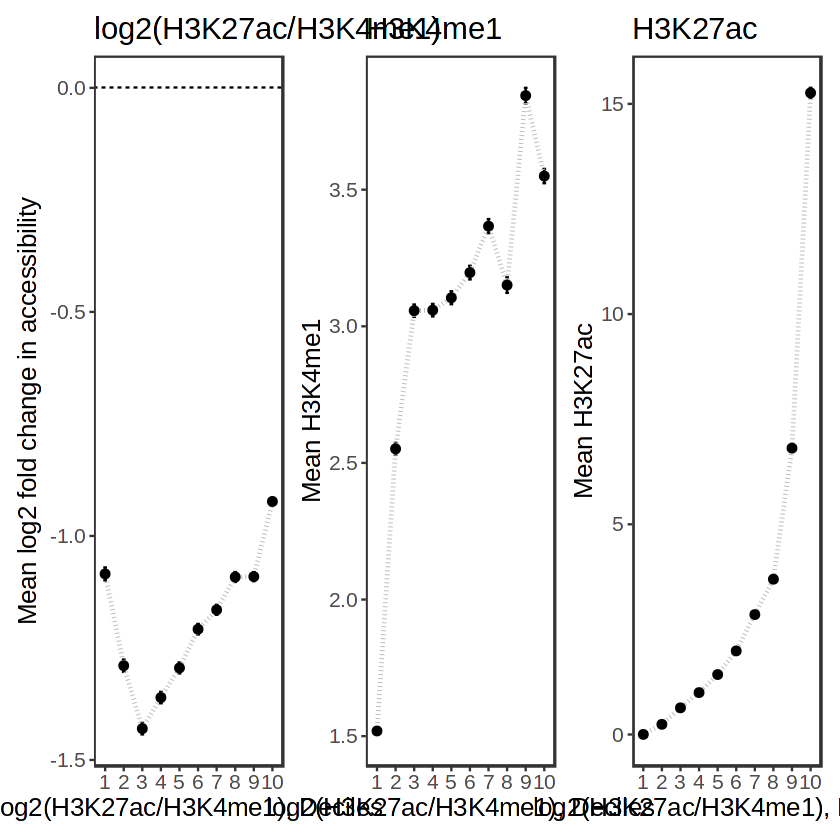

In [329]:
library(patchwork)
p1 | p2 | p3
ggsave("ratio.pdf", width=12, height=4)

In [310]:
model <- lm(lfc ~ ratio + TSS, 
    data=data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>% filter(TSS==FALSE))
summary(model)


Call:
lm(formula = lfc ~ ratio + TSS, data = data.frame(lfc = res_norm$logFC, 
    TSS = consensus_annot$TSS, change = res_norm$change, H3K4me1 = consensus_annot_2$H3K4me1, 
    H3K27ac = consensus_annot_2$H3K27ac, ratio = log2((consensus_annot_2$H3K27ac + 
        0.01)/(consensus_annot_2$H3K4me1 + 0.01))) %>% filter(TSS == 
    FALSE))

Residuals:
    Min      1Q  Median      3Q     Max 
-7.6030 -0.7696  0.0369  0.8999  3.5276 

Coefficients: (1 not defined because of singularities)
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) -1.156456   0.004346 -266.07   <2e-16 ***
ratio        0.028287   0.001573   17.98   <2e-16 ***
TSSTRUE            NA         NA      NA       NA    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.106 on 84047 degrees of freedom
Multiple R-squared:  0.003831,	Adjusted R-squared:  0.00382 
F-statistic: 323.3 on 1 and 84047 DF,  p-value: < 2.2e-16


In [349]:
test <- consensus_annot_2 %>% 
    mutate(ratio=log2((H3K27ac+.01)/(H3K4me1+.01)), lfc=res_norm$logFC) %>% 
    filter(!type %in% c("prom", "other_TSS") & H3K4me1_bed==TRUE) 
a <- lm(lfc ~ ratio, data=test) %>% summary()
b <- lm(lfc ~ H3K27ac, data=test) %>% summary()
c <- lm(lfc ~ ratio  + CTCF + DPF2   , data=test) %>% summary()
d <- lm(lfc ~ H3K27ac  + CTCF + DPF2   , data=test) %>% summary()

In [350]:
a$coefficients
a$adj.r.squared
b$coefficients
b$adj.r.squared
c$coefficients
c$adj.r.squared
d$coefficients
d$adj.r.squared

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-1.342013,0.005018418,-267.41747,0
ratio,0.123898,0.002676361,46.29345,0


[1] 0.05760443

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-1.58163507,0.0063835048,-247.76907,0
H3K27ac,0.02827783,0.0006396791,44.20627,0


[1] 0.05279303

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-1.12368524,0.0104282598,-107.75386,0.000000e+00
ratio,0.15299441,0.0025018391,61.15278,0.000000e+00
CTCF,0.04144161,0.0006142352,67.46864,0.000000e+00
DPF2,-0.16326020,0.0046086829,-35.42448,4.256738e-270


[1] 0.1954022

,Estimate,Std. Error,t value,Pr(>|t|)
(Intercept),-1.37211915,0.0105635535,-129.89182,0
H3K27ac,0.03631945,0.0006028987,60.24138,0
CTCF,0.03997622,0.0006127392,65.24183,0
DPF2,-0.18997506,0.0046757219,-40.63010,0


[1] 0.1931001

In [351]:
data.frame(lfc=res_norm$logFC, 
           TSS=consensus_annot$TSS, 
           change=res_norm$change, 
           H3K4me1=consensus_annot_2$H3K4me1, H3K27ac=consensus_annot_2$H3K27ac,
           ratio=log2((consensus_annot_2$H3K27ac+.01)/(consensus_annot_2$H3K4me1+.01))) %>%
    filter(TSS==FALSE) %>% 
    mutate(ratio_quantile=ntile(ratio,10)) %>%
    ggplot(aes(x=factor(ratio_quantile), y=lfc)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2, ) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    geom_hline(yintercept=0, linetype=2) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean log2 fold change in accessibility") + 
    ggtitle("log2(H3K27ac/H3K4me1)")

,seqnames,start,end,width,strand,TSS,H3K4me3,H3K4me1,H3K27ac,H3K27me3,CTCF,type,inDMSO,inBRM,ID
,<chr>,<int>,<int>,<int>,<chr>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<chr>,<lgl>,<lgl>,<int>
1,chr1,778361,779215,855,*,TRUE,TRUE,FALSE,TRUE,FALSE,TRUE,prom,TRUE,TRUE,1
2,chr1,804416,805076,661,*,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,other_nonTSS,TRUE,TRUE,2
3,chr1,817194,817588,395,*,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,other_TSS,TRUE,FALSE,3
4,chr1,826851,828112,1262,*,TRUE,TRUE,FALSE,TRUE,FALSE,FALSE,prom,TRUE,TRUE,4
5,chr1,838326,838675,350,*,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,other_nonTSS,TRUE,FALSE,5
6,chr1,857920,859154,1235,*,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,other_TSS,TRUE,TRUE,6


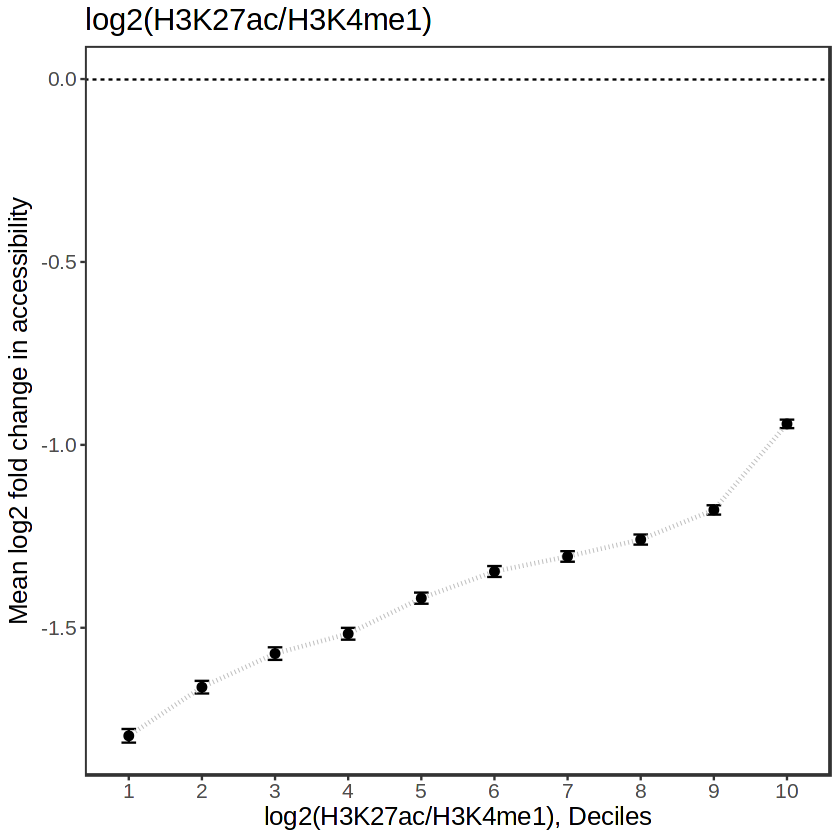

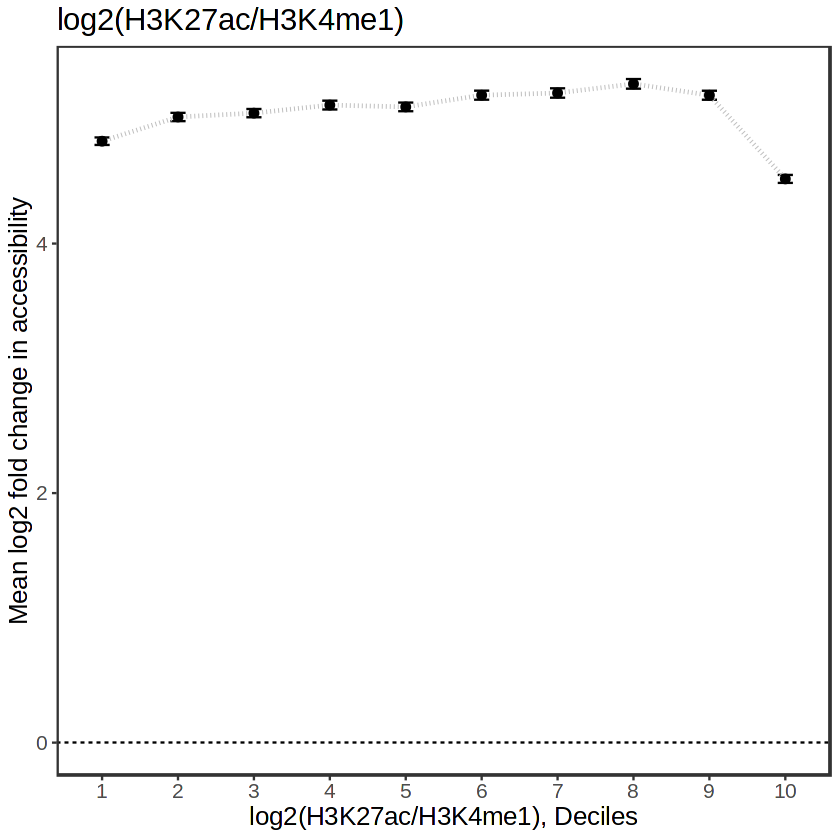

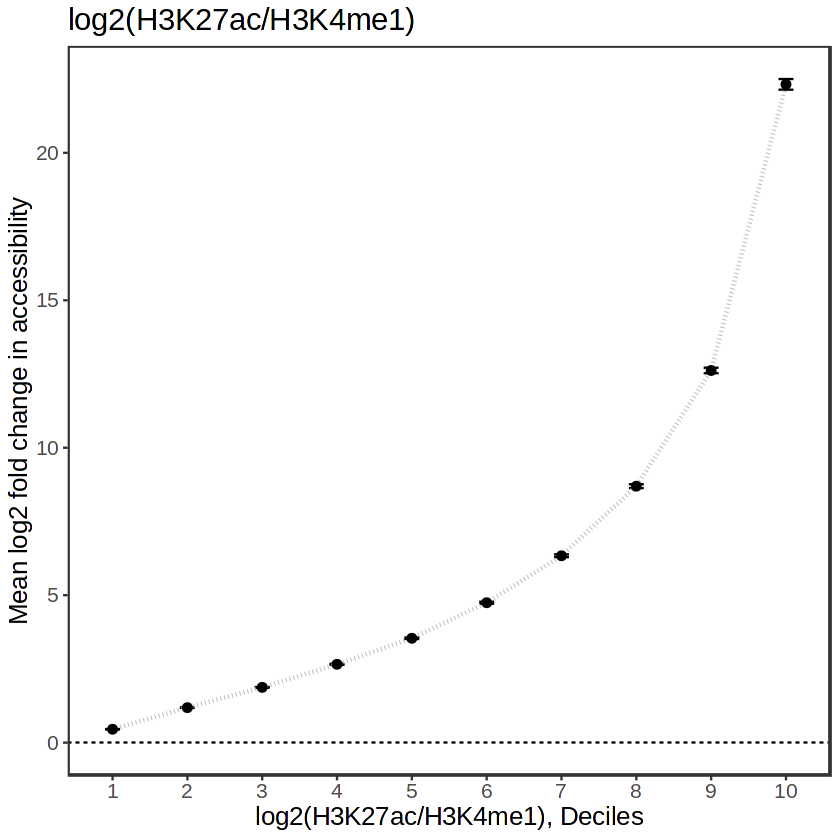

In [41]:
consensus_annot %>% mutate(lfc=res_norm$logFC, ratio=log2((H3K27ac + .01)/ (H3K4me1 + .01))) %>% filter(TSS==FALSE, H3K4me1_bed ==TRUE) %>% mutate(ratio_quantile=ntile(ratio,10)) %>% ggplot(aes(x=factor(ratio_quantile), y=lfc)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2, ) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    geom_hline(yintercept=0, linetype=2) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean log2 fold change in accessibility") + 
    ggtitle("log2(H3K27ac/H3K4me1)")

consensus_annot %>% mutate(lfc=res_norm$logFC, ratio=log2((H3K27ac + .01)/ (H3K4me1 + .01))) %>% filter(TSS==FALSE, H3K4me1_bed ==TRUE) %>% mutate(ratio_quantile=ntile(ratio,10)) %>% ggplot(aes(x=factor(ratio_quantile), y=H3K4me1)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2, ) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    geom_hline(yintercept=0, linetype=2) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean log2 fold change in accessibility") + 
    ggtitle("log2(H3K27ac/H3K4me1)")

consensus_annot %>% mutate(lfc=res_norm$logFC, ratio=log2((H3K27ac + .01)/ (H3K4me1 + .01))) %>% filter(TSS==FALSE, H3K4me1_bed ==TRUE) %>% mutate(ratio_quantile=ntile(ratio,10)) %>% ggplot(aes(x=factor(ratio_quantile), y=H3K27ac)) + 
    stat_summary(fun.data = mean_se, fun.args = list(mult = 1) , geom = "errorbar", aes(group=''), width=.2, color="black") +
    stat_summary(fun="mean", geom="line", aes(group=''), color="grey", linetype=3, linewidth=1) + 
    stat_summary(geom="point", fun="mean", size=2, ) + 
    #scale_fill_manual(values=colorRampPalette(brewer.pal(9,"Blues")[3:9])(10)) + 
    geom_hline(yintercept=0, linetype=2) + 
    xlab("log2(H3K27ac/H3K4me1), Deciles") + ylab("Mean log2 fold change in accessibility") + 
    ggtitle("log2(H3K27ac/H3K4me1)")

In [57]:
consensus_annot %>% mutate(lfc=res_norm$logFC ,ratio=log2((H3K27ac+.01)/(H3K4me1+.01)))%>% filter(TSS==FALSE, H3K4me1_bed==TRUE) %>% mutate(ratio_quantile=ntile(ratio,10)) %>% group_by(ratio_quantile) %>% summarize(mean(lfc), mean(CTCF))

ratio_quantile,mean(lfc),mean(CTCF)
<int>,<dbl>,<dbl>
1,-1.7953686,4.772930
2,-1.6623948,4.022576
3,-1.5705188,3.541392
4,-1.5163520,3.076723
5,-1.4190689,2.713486
6,-1.3462297,2.255531
7,-1.3050276,2.164644
8,-1.2588260,1.856469
9,-1.1778419,1.712444


`summarise()` has grouped output by 'change'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'change'. You can override using the
`.groups` argument.


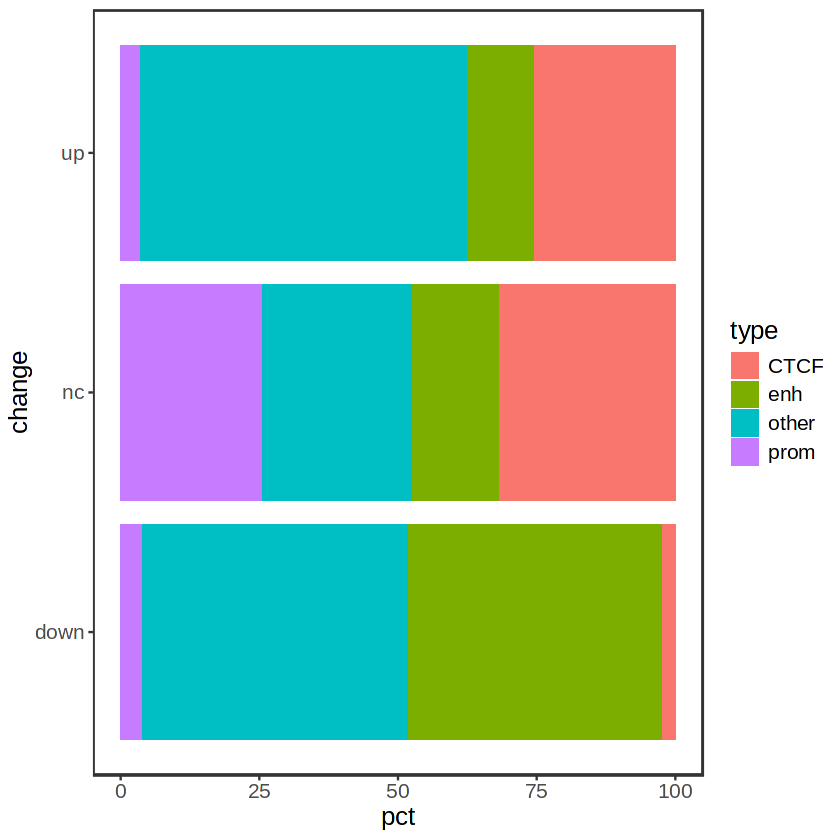

In [14]:
res_splitTSS$results %>% mutate(type = case_when(
                                        res_splitTSS$row_meta$type %in% c("active_enh", "poised_enh") ~ "enh",
                                        res_splitTSS$row_meta$type == "prom" ~ "prom", 
                                        res_splitTSS$row_meta$type == "CTCF_only" ~ "CTCF",
                                        TRUE ~ "other")) %>% 
group_by(change,type) %>% summarize(count=n()) %>% ungroup() %>% group_by(change) %>% summarize(type, count, pct=100*count/sum(count)) %>% ggplot(aes(y=change,x=pct, fill=type)) + geom_col()

In [9]:
temp <- res_splitTSS$results %>% mutate(type = case_when(
                                        res_splitTSS$row_meta$type %in% c("active_enh", "poised_enh") ~ "enh",
                                        res_splitTSS$row_meta$type == "prom" ~ "prom", 
                                        res_splitTSS$row_meta$type == "CTCF_only" ~ "CTCF",
                                        TRUE ~ "other"))

temp %>% group_by(change, type) %>% summarize(count=n()) %>% ungroup() %>% 
    group_by(change) %>% summarize(type, count, pct=100*count/sum(count)) %>% select(!count) %>% pivot_wider(values_from="pct", names_from="change") %>% `colnames<-`(c("type", "uninducible", "inducible")) %>% mutate(pval=pvals) %>% 
    ggplot(aes(x=factor(type, levels=c("prom", "CTCF", "other", "enh")), y=log2(inducible/uninducible))) + geom_hline(yintercept=0, linewidth=1) + 
    geom_segment(aes(x = type, xend = type, y = 0, yend = log2(inducible/uninducible)), color = "gray50", linewidth=1) + geom_point(shape=21,size=10, aes(fill=type)) + theme_bw() + 
    theme(panel.grid=element_blank(), text=element_text(size=15)) + 
    scale_fill_manual(values=c("enh"="#3182BD", "other"="grey", "CTCF" = "#5AAEAE", "prom" = "#D6604D" ), name='') + ylab("log2 enrichment in Dex inducible vs uninducible peaks") + xlab("cRE type") + ylim(-3,1) +
    geom_text(aes(label = paste("p =",format(pvals, digits=3)), vjust = ifelse(log2(inducible/uninducible) >= 0, -2, 3)), size = 3.5) + ggtitle("Dex inducible enhancers")

[1] "prom"                "other_TSS"           "other_nonTSS"       
[4] "poised_enh"          "CTCF_only"           "active_enh"         
[7] "poised_enh_H3K27me3"

`summarise()` has grouped output by 'change'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'change'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'change'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'change'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'change'. You can override using the
`.groups` argument.
Warning message:
“Returning more (or less) than 1 row per `summarise()` group was deprecated in
dplyr 1.1.0.
ℹ Please use `reframe()` instead.
ℹ When switching from `summarise()` to `reframe()`, remember that `reframe()`
  always returns an ungrouped data frame and adjust accordingly.”
`summarise()` has grouped output by 'change'. You can override using the
`.groups` argument.


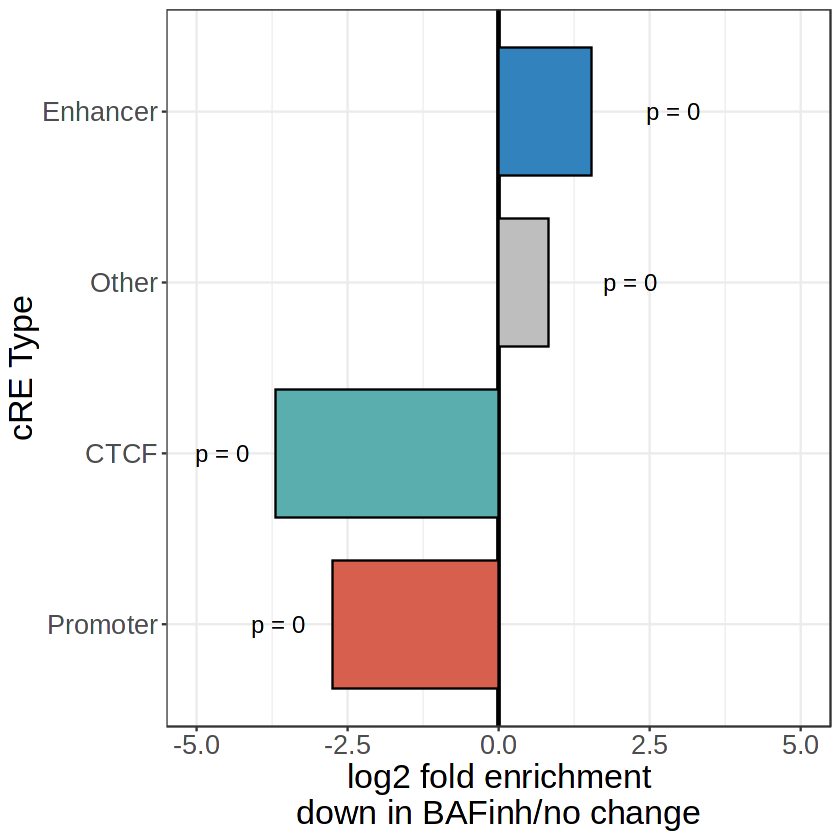

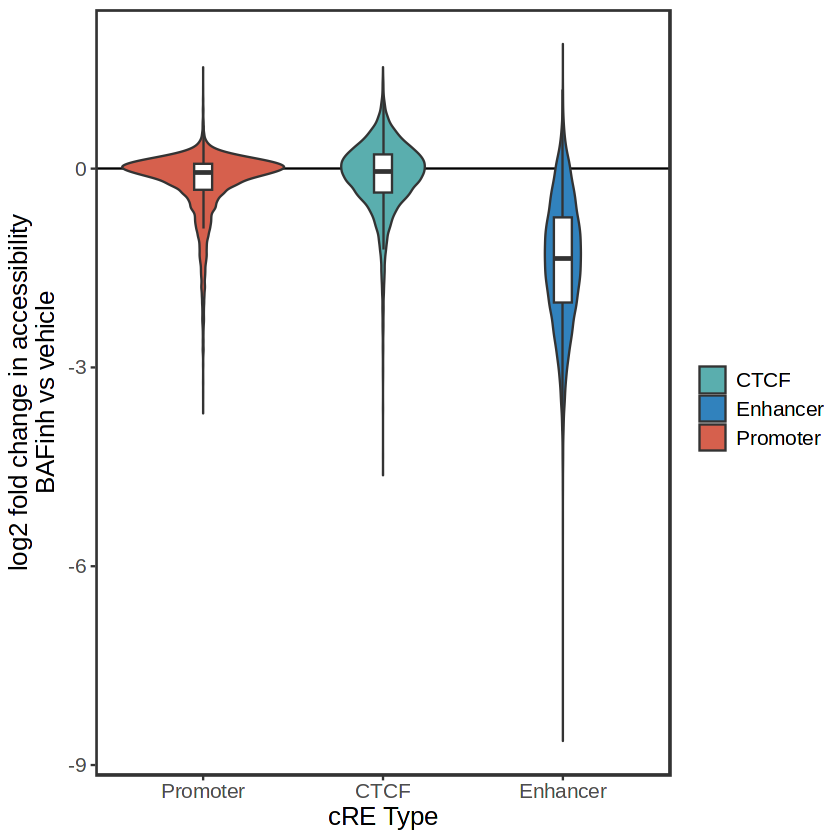

In [67]:
temp <- res_splitTSS$results %>% mutate(type = case_when(
                                        res_splitTSS$row_meta$type %in% c("active_enh", "poised_enh") ~ "Enhancer",
                                        res_splitTSS$row_meta$type == "prom" ~ "Promoter", 
                                        res_splitTSS$row_meta$type == "CTCF_only" ~ "CTCF",
                                        TRUE ~ "Other"))

pvals <- c("CTCF"=fisher.test(temp %>% filter(change!="up") %>% group_by(change, type=(type=="CTCF")) %>% summarize(count=n()) %>% pivot_wider(names_from=type, values_from=count)%>% column_to_rownames("change"))$p.value,
           "Enhancer"=fisher.test(temp %>% filter(change!="up")  %>% group_by(change, type=type=="Enhancer") %>% summarize(count=n()) %>% pivot_wider(names_from=type, values_from=count)%>% column_to_rownames("change"))$p.value,
           "Promoter"=fisher.test(temp %>% filter(change!="up")  %>% group_by(change, type=type=="Other") %>% summarize(count=n()) %>% pivot_wider(names_from=type, values_from=count)%>% column_to_rownames("change"))$p.value,
           "Promoter"=fisher.test(temp %>% filter(change!="up")  %>% group_by(change, type=type=="Promoter") %>% summarize(count=n()) %>% pivot_wider(names_from=type, values_from=count)%>% column_to_rownames("change"))$p.value)

temp %>% group_by(change, type) %>% summarize(count=n()) %>% ungroup() %>% 
    group_by(change) %>% summarize(type, count, pct=100*count/sum(count)) %>% select(!count) %>% pivot_wider(values_from="pct", names_from="change") %>% select(!up) %>% 
    ggplot(aes(x=factor(type, levels=c("Promoter", "CTCF", "Other", "Enhancer")), y=log2(down/nc))) + geom_hline(yintercept=0, linewidth=1) + geom_col(color="black", width=.75, aes(fill=type), show.legend=FALSE) + theme_bw() + coord_flip() + theme(text=element_text(size=20)) + xlab("cRE Type") + ylab("log2 fold enrichment\ndown in BAFinh/no change") +
    scale_fill_manual(values=c("Enhancer"="#3182BD", "Other"="grey", "CTCF" = "#5AAEAE", "Promoter" = "#D6604D" ), name='') + 
    geom_text(aes(label = paste("p =",format(pvals, digits=3)), hjust = ifelse(log2(down/nc) >= 0, -1, 1.5)), size = 5) + ylim(-5,5)

temp %>% filter(type!="Other") %>% ggplot(aes(x=factor(type, levels=c("Promoter", "CTCF", "Other", "Enhancer")), y=logFC)) + geom_hline(yintercept=0) + geom_violin(aes(fill=type)) + geom_boxplot(width=.1, outlier.shape=NA) + scale_fill_manual(values=c("Enhancer"="#3182BD", "Other"="grey", "CTCF" = "#5AAEAE", "Promoter" = "#D6604D" ), name='') + 
    xlab("cRE Type") + ylab("log2 fold change in accessibility\nBAFinh vs vehicle")

,logFC,logCPM,F,PValue,FDR,change,type,chr,start,end
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<int>,<int>
87037,-1.002260,6.038005,31.095433,1.281951e-05,6.140113e-05,down,active_enh,chr6,20877017,20878339
14028,-1.002252,4.319899,13.901482,1.153856e-03,2.687556e-03,down,active_enh,chr10,92567781,92568376
31154,-1.002105,5.750240,27.059196,3.153671e-05,1.279875e-04,down,active_enh,chr14,63745790,63746851
85752,-1.001913,3.449426,6.740145,1.641834e-02,2.836533e-02,down,active_enh,chr5,179836707,179837027
41513,-1.001681,4.021391,10.764486,3.386175e-03,6.921604e-03,down,active_enh,chr17,17757403,17758211
93218,-1.001519,4.410166,8.204443,8.964323e-03,1.645286e-02,down,active_enh,chr7,5584839,5585461
29636,-1.001504,4.856697,18.240719,3.063727e-04,8.574865e-04,down,active_enh,chr13,114048684,114049479
56142,-1.001451,4.985202,19.495003,2.149809e-04,6.358268e-04,down,active_enh,chr2,120261384,120263007
68905,-1.001394,3.534597,8.380164,8.357875e-03,1.545283e-02,down,active_enh,chr3,48945513,48946460


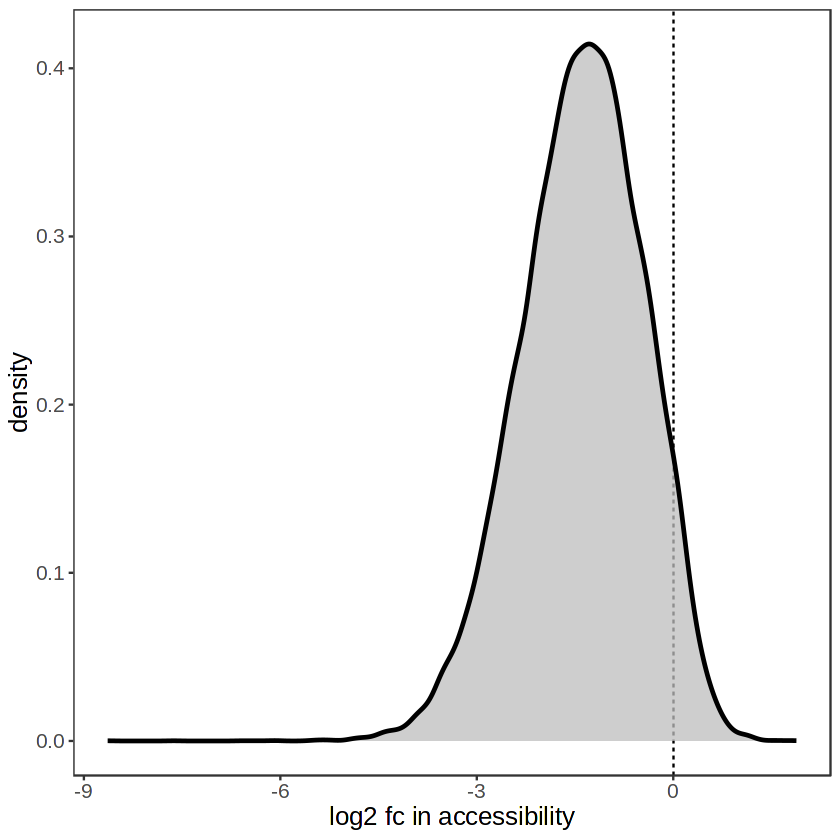

In [43]:
#res_splitTSS$results %>% mutate(type=res_splitTSS$row_meta$type, chr=res_splitTSS$row_meta$seqnames, start=res_splitTSS$row_meta$start, end=res_splitTSS$row_meta$end) %>% filter(res_splitTSS$row_meta$CTCF == FALSE) %>% filter(abs(logFC) < 0.5,type=="active_enh") %>% arrange(desc(logFC)) %>% head(20)

res_splitTSS$results %>%  mutate(type=res_splitTSS$row_meta$type, chr=res_splitTSS$row_meta$seqnames, start=res_splitTSS$row_meta$start, end=res_splitTSS$row_meta$end) %>% filter(res_splitTSS$row_meta$CTCF == FALSE)  %>% filter(type=="active_enh") %>%   filter(logFC < -1 & logFC > -2) %>% arrange((logFC)) %>% tail(20)


res_splitTSS$results[res_splitTSS$row_meta$type %in% c("active_enh", "poised_enh"),] %>% ggplot(aes(x=logFC)) + geom_vline(xintercept=0, linetype=2) + geom_density(fill="grey", linewidth=1, alpha=.75) + theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)) + xlab("log2 fc in accessibility")

In [25]:
?geom_density


geom_density {ggplot2},R Documentation
mapping,"Set of aesthetic mappings created by aes(). If specified and inherit.aes = TRUE (the default), it is combined with the default mapping at the top level of the plot. You must supply mapping if there is no plot mapping."
data,"The data to be displayed in this layer. There are three options: If NULL, the default, the data is inherited from the plot data as specified in the call to ggplot(). A data.frame, or other object, will override the plot data. All objects will be fortified to produce a data frame. See fortify() for which variables will be created. A function will be called with a single argument, the plot data. The return value must be a data.frame, and will be used as the layer data. A function can be created from a formula (e.g. ~ head(.x, 10))."
position,"A position adjustment to use on the data for this layer. This can be used in various ways, including to prevent overplotting and improving the display. The position argument accepts the following: The result of calling a position function, such as position_jitter(). This method allows for passing extra arguments to the position. A string naming the position adjustment. To give the position as a string, strip the function name of the position_ prefix. For example, to use position_jitter(), give the position as ""jitter"". For more information and other ways to specify the position, see the layer position documentation."
...,"Other arguments passed on to layer()'s params argument. These arguments broadly fall into one of 4 categories below. Notably, further arguments to the position argument, or aesthetics that are required can not be passed through .... Unknown arguments that are not part of the 4 categories below are ignored. Static aesthetics that are not mapped to a scale, but are at a fixed value and apply to the layer as a whole. For example, colour = ""red"" or linewidth = 3. The geom's documentation has an Aesthetics section that lists the available options. The 'required' aesthetics cannot be passed on to the params. Please note that while passing unmapped aesthetics as vectors is technically possible, the order and required length is not guaranteed to be parallel to the input data. When constructing a layer using a ⁠stat_*()⁠ function, the ... argument can be used to pass on parameters to the geom part of the layer. An example of this is stat_density(geom = ""area"", outline.type = ""both""). The geom's documentation lists which parameters it can accept. Inversely, when constructing a layer using a ⁠geom_*()⁠ function, the ... argument can be used to pass on parameters to the stat part of the layer. An example of this is geom_area(stat = ""density"", adjust = 0.5). The stat's documentation lists which parameters it can accept. The key_glyph argument of layer() may also be passed on through .... This can be one of the functions described as key glyphs, to change the display of the layer in the legend."
na.rm,"If FALSE, the default, missing values are removed with a warning. If TRUE, missing values are silently removed."
orientation,"The orientation of the layer. The default (NA) automatically determines the orientation from the aesthetic mapping. In the rare event that this fails it can be given explicitly by setting orientation to either ""x"" or ""y"". See the Orientation section for more detail."
show.legend,"logical. Should this layer be included in the legends? NA, the default, includes if any aesthetics are mapped. FALSE never includes, and TRUE always includes. It can also be a named logical vector to finely select the aesthetics to display."
inherit.aes,"If FALSE, overrides the default aesthetics, rather than combining with them. This is most useful for helper functions that define both data and aesthetics and shouldn't inherit behaviour from the default plot specification, e.g. borders()."
outline.type,"Type of the outline of the area; ""both"" draws both the upper and lower lines, ""upper""/""lower"" draws